# Satellite Land Cover Classification in Pakistan

This notebook demonstrates a complete end-to-end pipeline for high-purity, spatially balanced satellite dataset generation using Google Earth Engine (GEE), Sentinel-2 imagery, and ESA WorldCover data. It covers everything from credential authentication, stratified sampling, spatial dissimilarity filtering, and geographic grouping to downloading and validating the final 128x128 image patches stored directly in Google Drive.

## 1. Credentials & Earth Engine Authentication

### 1.1 Import Libraries & Centralize Setup

In [ ]:
import os
import time
from io import BytesIO
from collections import Counter, defaultdict

import ee
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import drive
from sklearn.neighbors import BallTree
from sklearn.cluster import MiniBatchKMeans

In [ ]:
import ee
from google.colab import drive

# Mount Google Drive centrally for the entire notebook
drive.mount("/content/drive")

# Authenticate with Google Earth Engine
ee.Authenticate()


Mounted at /content/drive


## 2. Earth Engine Initialization

### 2.1 Set GCP Project ID & Initialize API Connection

In [ ]:
PROJECT_ID = "land-cover-512908"

ee.Initialize(project=PROJECT_ID)

print("Earth Engine initialized successfully!")

Earth Engine initialized successfully!


## 3. Data Collections Setup

### 3.1 Define Sentinel-2 Harmonized Collection

In [ ]:
sentinel = ee.ImageCollection(
    "COPERNICUS/S2_SR_HARMONIZED"
)

print("Sentinel collection created.")
print("First image:", sentinel.first().getInfo())

Sentinel collection created.
First image: {'type': 'Image', 'bands': [{'id': 'B1', 'data_type': {'type': 'PixelType', 'precision': 'int', 'min': 0, 'max': 65535}, 'dimensions': [1830, 1830], 'crs': 'EPSG:32633', 'crs_transform': [60, 0, 600000, 0, -60, 6900000]}, {'id': 'B2', 'data_type': {'type': 'PixelType', 'precision': 'int', 'min': 0, 'max': 65535}, 'dimensions': [10980, 10980], 'crs': 'EPSG:32633', 'crs_transform': [10, 0, 600000, 0, -10, 6900000]}, {'id': 'B3', 'data_type': {'type': 'PixelType', 'precision': 'int', 'min': 0, 'max': 65535}, 'dimensions': [10980, 10980], 'crs': 'EPSG:32633', 'crs_transform': [10, 0, 600000, 0, -10, 6900000]}, {'id': 'B4', 'data_type': {'type': 'PixelType', 'precision': 'int', 'min': 0, 'max': 65535}, 'dimensions': [10980, 10980], 'crs': 'EPSG:32633', 'crs_transform': [10, 0, 600000, 0, -10, 6900000]}, {'id': 'B5', 'data_type': {'type': 'PixelType', 'precision': 'int', 'min': 0, 'max': 65535}, 'dimensions': [5490, 5490], 'crs': 'EPSG:32633', 'crs_t

In [ ]:
worldcover = ee.ImageCollection(
    "ESA/WorldCover/v200"
)

print("WorldCover collection created.")
print("First image:", worldcover.first().getInfo())

WorldCover collection created.
First image: {'type': 'Image', 'bands': [{'id': 'Map', 'data_type': {'type': 'PixelType', 'precision': 'int', 'min': 0, 'max': 255}, 'dimensions': [4320000, 1728000], 'crs': 'EPSG:4326', 'crs_transform': [8.333333333333333e-05, 0, -180, 0, -8.333333333333333e-05, 84]}], 'version': 1746488833928724, 'id': 'ESA/WorldCover/v200/2021', 'properties': {'Map_class_names': ['Tree cover', 'Shrubland', 'Grassland', 'Cropland', 'Built-up', 'Bare / sparse vegetation', 'Snow and ice', 'Permanent water bodies', 'Herbaceous wetland', 'Mangroves', 'Moss and lichen'], 'system:time_start': 1609459200000, 'system:footprint': {'type': 'LinearRing', 'coordinates': [[-180, -90], [180, -90], [180, 90], [-180, 90], [-180, -90]]}, 'system:time_end': 1640991600000, 'Map_class_palette': ['006400', 'ffbb22', 'ffff4c', 'f096ff', 'fa0000', 'b4b4b4', 'f0f0f0', '0064c8', '0096a0', '00cf75', 'fae6a0'], 'Map_class_values': [10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 100], 'system:asset_size'

### 3.2 Define ESA WorldCover Collection

## 4. Region of Interest & Class Definition

### 4.1 Define Regions of Interest and Target Classes

In [ ]:
# Define Pakistan's boundary
countries = ee.FeatureCollection("FAO/GAUL/2015/level0")

pakistan = countries.filter(
    ee.Filter.eq("ADM0_NAME", "Pakistan")
)

pakistan_geometry = pakistan.geometry()

# Our five land-cover classes from ESA WorldCover
CLASS_NAMES = {
    10: "Tree_Cover",
    40: "Cropland",
    50: "Built_Up",
    60: "Bare_Sparse_Vegetation",
    80: "Permanent_Water"
}

print("Country:", pakistan.first().get("ADM0_NAME").getInfo())
print("Country boundary loaded successfully!")
print("Classes:", CLASS_NAMES)

Country: Pakistan
Country boundary loaded successfully!
Classes: {10: 'Tree_Cover', 40: 'Cropland', 50: 'Built_Up', 60: 'Bare_Sparse_Vegetation', 80: 'Permanent_Water'}


## 5. Localized Stratified Sampling Test

### 5.1 Lahore Stratified Sample Test

In [ ]:
# Load the WorldCover map
worldcover = ee.ImageCollection(
    "ESA/WorldCover/v200"
).first().select("Map")

# Use a small test region around Lahore
test_region = ee.Geometry.Rectangle([
    74.20, 31.35,
    74.50, 31.60
])

target_classes = [10, 40, 50, 60, 80]

# Explicitly mask out all other land-cover classes
target_mask = (
    worldcover.eq(10)
    .Or(worldcover.eq(40))
    .Or(worldcover.eq(50))
    .Or(worldcover.eq(60))
    .Or(worldcover.eq(80))
)

filtered_worldcover = worldcover.updateMask(target_mask)

# Sample only the five target classes
test_candidates = filtered_worldcover.stratifiedSample(
    numPoints=3,
    classBand="Map",
    region=test_region,
    scale=100,
    classValues=target_classes,
    classPoints=[3, 3, 3, 3, 3],
    seed=42,
    geometries=True,
    tileScale=4
)

# Retrieve and inspect the results
features = test_candidates.getInfo()["features"]

class_ids = [
    feature["properties"]["Map"]
    for feature in features
]

print("Sampling test completed!")
print("Candidate count:", len(features))
print("Class counts:", Counter(class_ids))
print(
    "Unexpected classes:",
    sorted(set(class_ids) - set(CLASS_NAMES))
)

Sampling test completed!
Candidate count: 15
Class counts: Counter({10: 3, 40: 3, 50: 3, 60: 3, 80: 3})
Unexpected classes: []


In [ ]:
# Inspect the class IDs returned by the existing sample
class_ids = [
    feature["properties"]["Map"]
    for feature in features
]

print("Class counts:", Counter(class_ids))
print("Unexpected class IDs:", sorted(set(class_ids) - set(CLASS_NAMES)))

Class counts: Counter({10: 3, 40: 3, 50: 3, 60: 3, 80: 3})
Unexpected class IDs: []


## 6. Nationwide Candidate Stratified Sampling

### 6.1 Nationwide Stratified Sample Generation

In [ ]:
# Sample 10 points per target class across Pakistan
pakistan_candidates = filtered_worldcover.stratifiedSample(
    numPoints=10,
    classBand="Map",
    region=pakistan_geometry,
    scale=100,
    classValues=target_classes,
    classPoints=[10, 10, 10, 10, 10],
    seed=42,
    geometries=True,
    tileScale=4
)

# Retrieve and inspect results
pakistan_features = pakistan_candidates.getInfo()["features"]

pakistan_class_ids = [
    feature["properties"]["Map"]
    for feature in pakistan_features
]

print("Nationwide sampling completed!")
print("Total candidates:", len(pakistan_features))
print("Class counts:", Counter(pakistan_class_ids))
print(
    "Unexpected classes:",
    sorted(set(pakistan_class_ids) - set(CLASS_NAMES))
)

Nationwide sampling completed!
Total candidates: 50
Class counts: Counter({10: 10, 40: 10, 50: 10, 60: 10, 80: 10})
Unexpected classes: []


In [ ]:
rows = []

for feature in pakistan_features:
    class_id = feature["properties"]["Map"]
    longitude, latitude = feature["geometry"]["coordinates"]

    rows.append({
        "class_id": class_id,
        "class_name": CLASS_NAMES[class_id],
        "longitude": longitude,
        "latitude": latitude
    })

candidates_df = pd.DataFrame(rows)

print("Candidates by class:")
display(candidates_df["class_name"].value_counts().to_frame("count"))

print("\nFirst 10 candidate locations:")
display(candidates_df.head(10))

Candidates by class:


,count
class_name,
Tree_Cover,10
Cropland,10
Built_Up,10
Bare_Sparse_Vegetation,10
Permanent_Water,10



First 10 candidate locations:


,class_id,class_name,longitude,latitude
0,10,Tree_Cover,72.302178,35.468068
1,10,Tree_Cover,73.566108,32.955480
2,10,Tree_Cover,66.789217,24.955084
3,10,Tree_Cover,73.023525,32.677002
4,10,Tree_Cover,72.685759,31.288207
5,10,Tree_Cover,72.092871,32.624900
6,10,Tree_Cover,72.321941,34.869790
7,10,Tree_Cover,72.917524,31.385225
8,10,Tree_Cover,73.155578,33.909491
9,10,Tree_Cover,67.614769,24.294822


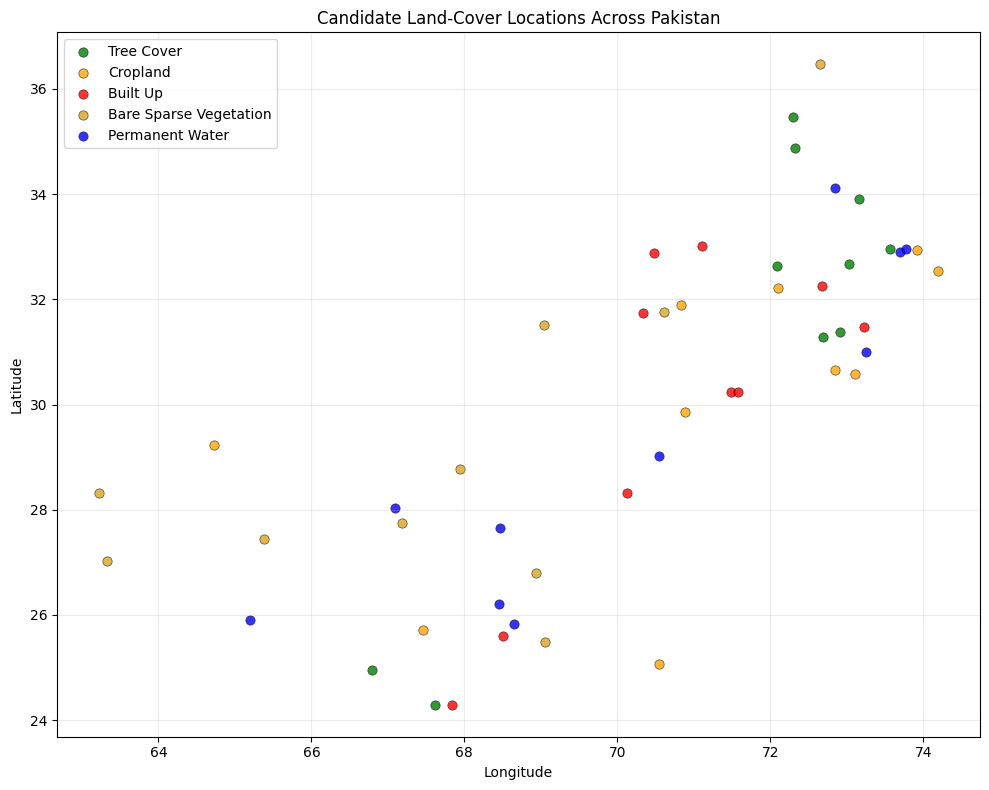

In [ ]:
class_colors = {
    "Tree_Cover": "green",
    "Cropland": "orange",
    "Built_Up": "red",
    "Bare_Sparse_Vegetation": "goldenrod",
    "Permanent_Water": "blue"
}

plt.figure(figsize=(10, 8))

for class_name, color in class_colors.items():
    subset = candidates_df[
        candidates_df["class_name"] == class_name
    ]

    plt.scatter(
        subset["longitude"],
        subset["latitude"],
        c=color,
        label=class_name.replace("_", " "),
        s=45,
        alpha=0.8,
        edgecolors="black",
        linewidths=0.4
    )

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Candidate Land-Cover Locations Across Pakistan")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 7. Preliminary Patch Extraction & Visualizations

### 7.1 Single Patch Selection for Visual Checks

In [ ]:
# Select one candidate each for tree cover, cropland, and built-up
test_classes = [10, 40, 50]

test_points = {}

for feature in pakistan_features:
    class_id = feature["properties"]["Map"]

    if class_id in test_classes and class_id not in test_points:
        test_points[class_id] = feature["geometry"]["coordinates"]

    if len(test_points) == len(test_classes):
        break

for class_id, coordinates in test_points.items():
    print(
        CLASS_NAMES[class_id],
        "— longitude, latitude:",
        coordinates
    )

Tree_Cover — longitude, latitude: [72.302178170735, 35.46806761780079]
Cropland — longitude, latitude: [70.54327684442899, 25.06916988883321]
Built_Up — longitude, latitude: [71.10202895115131, 33.017463522722736]


In [ ]:
# Sentinel-2 Surface Reflectance Harmonized collection
sentinel = ee.ImageCollection(
    "COPERNICUS/S2_SR_HARMONIZED"
)

# Search for a clear image around each candidate point
for class_id, coordinates in test_points.items():

    point = ee.Geometry.Point(coordinates)

    images = (
        sentinel
        .filterBounds(point)
        .filterDate("2021-01-01", "2022-01-01")
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20))
        .sort("CLOUDY_PIXEL_PERCENTAGE")
    )

    # Get one image instead of requesting the full collection
    image = images.first()

    print("\nClass:", CLASS_NAMES[class_id])
    print("Matching image available:", image is not None)

    if image is not None:
        print("Image metadata:")
        print(
            image.toDictionary([
                "CLOUDY_PIXEL_PERCENTAGE",
                "system:time_start",
                "MGRS_TILE"
            ]).getInfo()
        )


Class: Tree_Cover
Matching image available: True
Image metadata:
{'CLOUDY_PIXEL_PERCENTAGE': 1.3e-05, 'MGRS_TILE': '42SYE', 'system:time_start': 1634278160043}

Class: Cropland
Matching image available: True
Image metadata:
{'CLOUDY_PIXEL_PERCENTAGE': 0.009299, 'MGRS_TILE': '42RXN', 'system:time_start': 1613282532498}

Class: Built_Up
Matching image available: True
Image metadata:
{'CLOUDY_PIXEL_PERCENTAGE': 0, 'MGRS_TILE': '42SXB', 'system:time_start': 1619590198663}


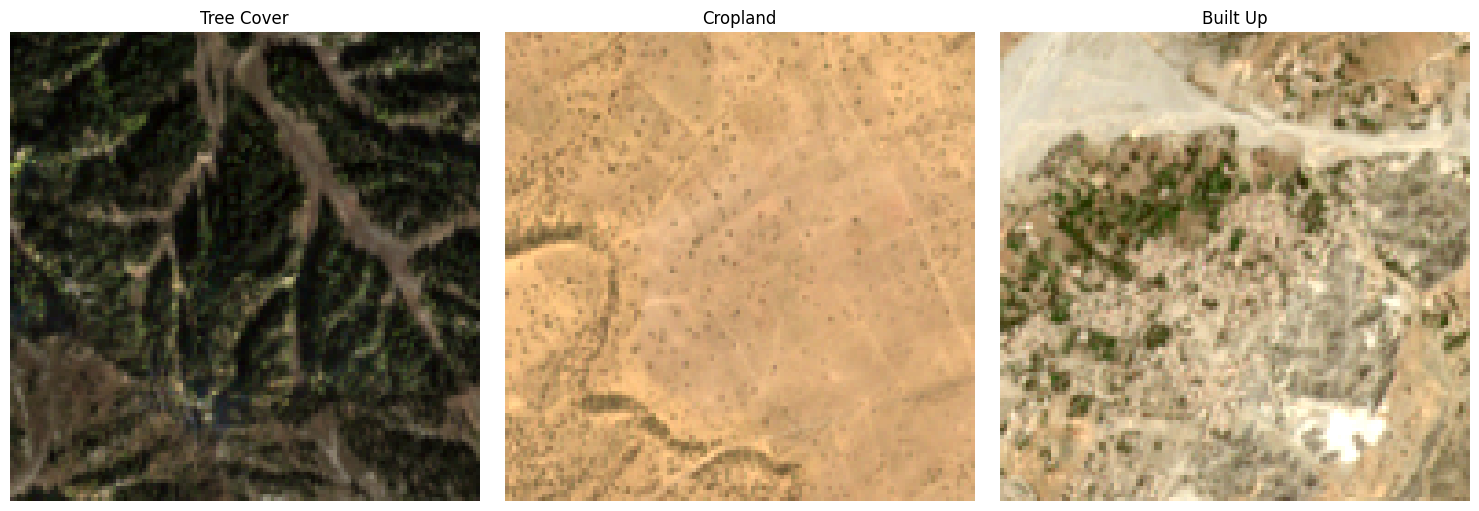

In [ ]:
patch_size_m = 1280  # 128 pixels × 10 metres

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (class_id, coordinates) in zip(axes, test_points.items()):
    point = ee.Geometry.Point(coordinates)

    image = (
        sentinel
        .filterBounds(point)
        .filterDate("2021-01-01", "2022-01-01")
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20))
        .sort("CLOUDY_PIXEL_PERCENTAGE")
        .first()
    )

    # Define the patch around the candidate point
    patch_region = point.buffer(patch_size_m / 2).bounds()

    # RGB visualization, scaled to 8-bit values
    rgb = image.select(["B4", "B3", "B2"]).visualize(
        min=0,
        max=3000,
        gamma=1.2
    )

    # Request a small thumbnail from Earth Engine
    thumbnail_url = rgb.getThumbURL({
        "region": patch_region,
        "dimensions": "128x128",
        "format": "png"
    })

    response = requests.get(thumbnail_url, timeout=60)
    response.raise_for_status()

    satellite_patch = np.array(
        Image.open(BytesIO(response.content)).convert("RGB")
    )

    ax.imshow(satellite_patch)
    ax.set_title(CLASS_NAMES[class_id].replace("_", " "))
    ax.axis("off")

plt.tight_layout()
plt.show()

## 8. Patch Purity and Class Composition Analysis

### 8.1 Evaluate Purity within 1.28 km Patches

In [ ]:
# Check the class composition of each 1.28 km patch
worldcover = ee.ImageCollection(
    "ESA/WorldCover/v200"
).first().select("Map")

patch_size_m = 1280

for class_id, coordinates in test_points.items():
    point = ee.Geometry.Point(coordinates)
    region = point.buffer(patch_size_m / 2).bounds()

    histogram = worldcover.reduceRegion(
        reducer=ee.Reducer.frequencyHistogram(),
        geometry=region,
        scale=10,
        maxPixels=200000,
        tileScale=4
    ).get("Map").getInfo()

    total = sum(histogram.values())
    target_pixels = histogram.get(str(class_id), 0)
    purity = 100 * target_pixels / total if total else 0

    print(f"\n{CLASS_NAMES[class_id]}")
    print(f"Target-class purity: {purity:.1f}%")
    print("Most common classes:", sorted(
        histogram.items(),
        key=lambda item: item[1],
        reverse=True
    )[:5])


Tree_Cover
Target-class purity: 72.4%
Most common classes: [('10', 14531.172549019604), ('30', 5453.776470588225), ('60', 53), ('100', 16), ('40', 5)]

Cropland
Target-class purity: 42.8%
Most common classes: [('40', 7724.090196078408), ('60', 5948.066666666651), ('20', 3851.619607843132), ('10', 511.8235294117645)]

Built_Up
Target-class purity: 27.7%
Most common classes: [('60', 8078.101960784304), ('50', 5401.792156862745), ('40', 2219.3921568627443), ('30', 2141.894117647055), ('20', 1020.1764705882355)]


### 8.2 Contrast 1.28 km Purity vs. 640 m Purity

In [ ]:
# Compare WorldCover class purity at two patch sizes

worldcover = ee.ImageCollection(
    "ESA/WorldCover/v200"
).first().select("Map")

patch_sizes = {
    "128x128 (1280m)": 1280,
    "64x64 (640m)": 640
}

for class_id, coordinates in test_points.items():
    point = ee.Geometry.Point(coordinates)

    print(f"\n{'=' * 40}")
    print(f"Class: {CLASS_NAMES[class_id]}")

    for size_name, size_m in patch_sizes.items():
        region = point.buffer(size_m / 2).bounds()

        # Count the actual 10m raster pixels belonging to each class
        histogram = worldcover.reduceRegion(
            reducer=ee.Reducer.frequencyHistogram(),
            geometry=region,
            scale=10,
            maxPixels=200000,
            tileScale=4
        ).get("Map").getInfo()

        total_pixels = sum(histogram.values())
        target_pixels = histogram.get(str(class_id), 0)

        purity = (
            100 * target_pixels / total_pixels
            if total_pixels else 0
        )

        print(f"{size_name}: {purity:.1f}% purity")


Class: Tree_Cover
128x128 (1280m): 72.4% purity
64x64 (640m): 72.1% purity

Class: Cropland
128x128 (1280m): 42.8% purity
64x64 (640m): 57.5% purity

Class: Built_Up
128x128 (1280m): 27.7% purity
64x64 (640m): 53.6% purity


In [ ]:
# Find high-purity candidate areas for tree cover

worldcover = ee.ImageCollection(
    "ESA/WorldCover/v200"
).first().select("Map")

target_class = 10  # Tree cover
purity_threshold = 0.80

# Binary image: 1 where the pixel is tree cover, 0 elsewhere
is_target = worldcover.eq(target_class).rename("target")

# Approximate 640m square neighborhood at 10m resolution
neighborhood = ee.Kernel.square(
    radius=32,
    units="pixels",
    normalize=False
)

# Calculate the proportion of target-class pixels around each pixel
local_purity = is_target.reduceNeighborhood(
    reducer=ee.Reducer.mean(),
    kernel=neighborhood
).rename("purity")

# Keep only locations with at least 80% target-class pixels
high_purity = (
    worldcover.eq(target_class)
    .And(local_purity.gte(purity_threshold))
    .selfMask()
    .rename("Map")
)

# Sample up to 10 qualifying points within Pakistan
tree_candidates = high_purity.stratifiedSample(
    numPoints=10,
    classBand="Map",
    region=pakistan_geometry,
    scale=10,
    geometries=True,
    seed=42,
    tileScale=4
)

tree_features = tree_candidates.getInfo()["features"]

print("High-purity tree-cover candidates:", len(tree_features))

for feature in tree_features:
    print(feature["geometry"]["coordinates"])

EEException: Earth Engine client library not initialized. See http://goo.gle/ee-auth.

In [ ]:
### This part is a little out of order. the above one needs to run after this.
# STEP 1: Sample candidate locations across Pakistan

candidate_count_per_class = 20

candidates = filtered_worldcover.stratifiedSample(
    numPoints=candidate_count_per_class,
    classBand="Map",
    region=pakistan_geometry,
    scale=100,
    classValues=target_classes,
    classPoints=[candidate_count_per_class] * len(target_classes),
    seed=42,
    geometries=True,
    tileScale=4
)

candidate_features = candidates.getInfo()["features"]

print("Total candidate locations:", len(candidate_features))

# Check how many candidates we obtained for each class
from collections import Counter

candidate_counts = Counter(
    feature["properties"]["Map"]
    for feature in candidate_features
)

for class_id in target_classes:
    print(
        f"{CLASS_NAMES[class_id]}: "
        f"{candidate_counts.get(class_id, 0)} candidates"
    )


## 9. Comprehensive Large Pool Candidate Sampling

### 9.1 Evaluate Purity of Evaluation Candidate Batches

In [ ]:
candidates_by_class = defaultdict(list)

for feature in candidate_features:
    class_id = feature["properties"]["Map"]
    candidates_by_class[class_id].append(feature)

for class_id in target_classes:
    print(
        CLASS_NAMES[class_id],
        "available:", len(candidates_by_class[class_id])
    )

Tree_Cover available: 20
Cropland available: 20
Built_Up available: 20
Bare_Sparse_Vegetation available: 20
Permanent_Water available: 20


In [ ]:
# Use smaller 640 m x 640 m patches
patch_size_m = 640
test_per_class = 2

# Select 2 candidate locations per class
test_features = []

for class_id in target_classes:
    test_features.extend(
        candidates_by_class[class_id][:test_per_class]
    )

print("Patches to evaluate:", len(test_features))

# Build patch regions around candidate points
patches = ee.FeatureCollection([
    ee.Feature(
        ee.Geometry.Point(feature["geometry"]["coordinates"])
        .buffer(patch_size_m / 2)
        .bounds(),
        {
            "class_id": feature["properties"]["Map"],
            "longitude": feature["geometry"]["coordinates"][0],
            "latitude": feature["geometry"]["coordinates"][1]
        }
    )
    for feature in test_features
])

# Calculate class histograms only within these 10 patches
worldcover = ee.ImageCollection(
    "ESA/WorldCover/v200"
).first().select("Map")

results = worldcover.reduceRegions(
    collection=patches,
    reducer=ee.Reducer.frequencyHistogram(),
    scale=10,
    tileScale=4
).getInfo()["features"]

# Calculate purity for each patch
rows = []

for feature in results:
    props = feature["properties"]
    class_id = int(props["class_id"])
    histogram = props.get("histogram", {})

    total_pixels = sum(histogram.values())
    target_pixels = histogram.get(str(class_id), 0)

    purity = (
        100 * target_pixels / total_pixels
        if total_pixels else 0
    )

    rows.append({
        "Class": CLASS_NAMES[class_id],
        "Latitude": round(props["latitude"], 5),
        "Longitude": round(props["longitude"], 5),
        "Purity (%)": round(purity, 1),
        "Meets 80% threshold": purity >= 80
    })

purity_df = pd.DataFrame(rows)
display(purity_df.sort_values(["Class", "Purity (%)"],
                              ascending=[True, False]))

Patches to evaluate: 10


,Class,Latitude,Longitude,Purity (%),Meets 80% threshold
7,Bare_Sparse_Vegetation,27.01762,63.32262,100.0,True
6,Bare_Sparse_Vegetation,36.46699,72.64893,87.1,True
4,Built_Up,33.01746,71.10203,53.5,False
5,Built_Up,24.29662,67.83486,10.8,False
3,Cropland,32.54136,74.19313,68.9,False
2,Cropland,25.06917,70.54328,57.5,False
9,Permanent_Water,29.01727,70.54418,50.2,False
8,Permanent_Water,27.65632,68.47176,12.4,False
0,Tree_Cover,35.46807,72.30218,72.1,False
1,Tree_Cover,32.95548,73.56611,63.5,False


In [ ]:
patch_size_m = 640
batch_size = 20

worldcover = ee.ImageCollection(
    "ESA/WorldCover/v200"
).first().select("Map")

# Create 100 small patch regions from existing candidates
patch_features = []

for feature in candidate_features:
    class_id = int(feature["properties"]["Map"])
    lon, lat = feature["geometry"]["coordinates"]

    region = (
        ee.Geometry.Point([lon, lat])
        .buffer(patch_size_m / 2)
        .bounds()
    )

    patch_features.append(
        ee.Feature(region, {
            "class_id": class_id,
            "longitude": lon,
            "latitude": lat
        })
    )

# Evaluate in batches rather than one large request
rows = []

for start in range(0, len(patch_features), batch_size):
    batch = ee.FeatureCollection(
        patch_features[start:start + batch_size]
    )

    results = worldcover.reduceRegions(
        collection=batch,
        reducer=ee.Reducer.frequencyHistogram(),
        scale=10,
        tileScale=4
    ).getInfo()["features"]

    for result in results:
        props = result["properties"]
        class_id = int(props["class_id"])
        histogram = props.get("histogram", {})

        total = sum(histogram.values())
        target_pixels = histogram.get(str(class_id), 0)
        purity = 100 * target_pixels / total if total else 0

        rows.append({
            "class_id": class_id,
            "Class": CLASS_NAMES[class_id],
            "Latitude": props["latitude"],
            "Longitude": props["longitude"],
            "Purity (%)": round(purity, 1)
        })

    print(
        f"Evaluated {min(start + batch_size, len(patch_features))}"
        f" / {len(patch_features)} patches"
    )

purity_df = pd.DataFrame(rows)

# Show the best candidates for each class
best_candidates = (
    purity_df.sort_values("Purity (%)", ascending=False)
    .groupby("class_id")
    .head(5)
    .sort_values(["class_id", "Purity (%)"],
                 ascending=[True, False])
)

display(best_candidates[
    ["Class", "Latitude", "Longitude", "Purity (%)"]
].reset_index(drop=True))

print("\nCandidates meeting the 80% threshold:")
display(
    purity_df[purity_df["Purity (%)"] >= 80]
    .sort_values(["Class", "Purity (%)"],
                 ascending=[True, False])
    .reset_index(drop=True)
)

Evaluated 20 / 100 patches
Evaluated 40 / 100 patches
Evaluated 60 / 100 patches
Evaluated 80 / 100 patches
Evaluated 100 / 100 patches


,Class,Latitude,Longitude,Purity (%)
0,Tree_Cover,33.972373,72.731573,93.0
1,Tree_Cover,34.126883,72.705522,88.9
2,Tree_Cover,33.909491,73.155578,78.6
3,Tree_Cover,35.468068,72.302178,72.1
4,Tree_Cover,32.677002,73.023525,71.4
5,Cropland,25.818365,68.310963,100.0
6,Cropland,30.665674,72.846557,96.2
7,Cropland,27.042769,68.606509,95.3
8,Cropland,30.589317,73.109764,90.8
9,Cropland,29.222980,64.730279,87.3



Candidates meeting the 80% threshold:


,class_id,Class,Latitude,Longitude,Purity (%)
0,60,Bare_Sparse_Vegetation,27.017616,63.322619,100.0
1,60,Bare_Sparse_Vegetation,28.321071,63.221109,100.0
2,60,Bare_Sparse_Vegetation,27.440722,65.382456,100.0
3,60,Bare_Sparse_Vegetation,28.860060,69.799472,100.0
4,60,Bare_Sparse_Vegetation,27.905151,63.422332,100.0
5,60,Bare_Sparse_Vegetation,29.158301,65.173148,100.0
6,60,Bare_Sparse_Vegetation,28.381258,63.290279,100.0
7,60,Bare_Sparse_Vegetation,30.923491,67.061407,99.7
8,60,Bare_Sparse_Vegetation,29.187945,66.225075,99.4
9,60,Bare_Sparse_Vegetation,27.741658,67.190764,99.2


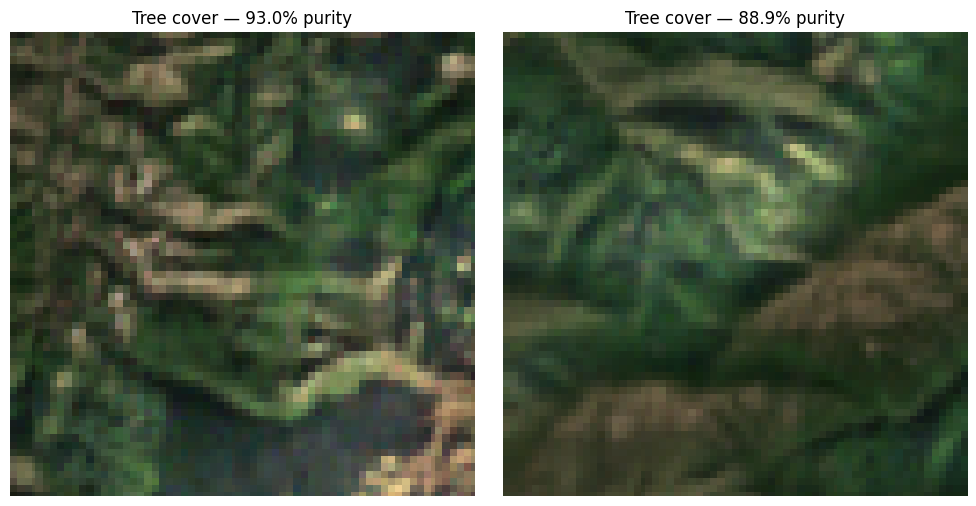

In [ ]:
tree_test_points = [
    (33.972373, 72.731573, 93.0),
    (34.126883, 72.705522, 88.9)
]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, (lat, lon, purity) in zip(axes, tree_test_points):
    point = ee.Geometry.Point([lon, lat])

    image = (
        sentinel
        .filterBounds(point)
        .filterDate("2021-01-01", "2022-01-01")
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20))
        .sort("CLOUDY_PIXEL_PERCENTAGE")
        .first()
    )

    region = point.buffer(320).bounds()

    rgb = image.select(["B4", "B3", "B2"]).visualize(
        min=0, max=3000, gamma=1.2
    )

    url = rgb.getThumbURL({
        "region": region,
        "dimensions": "128x128",
        "format": "png"
    })

    response = requests.get(url, timeout=60)
    response.raise_for_status()

    patch = np.array(
        Image.open(BytesIO(response.content)).convert("RGB")
    )

    ax.imshow(patch)
    ax.set_title(f"Tree cover — {purity}% purity")
    ax.axis("off")

plt.tight_layout()
plt.show()

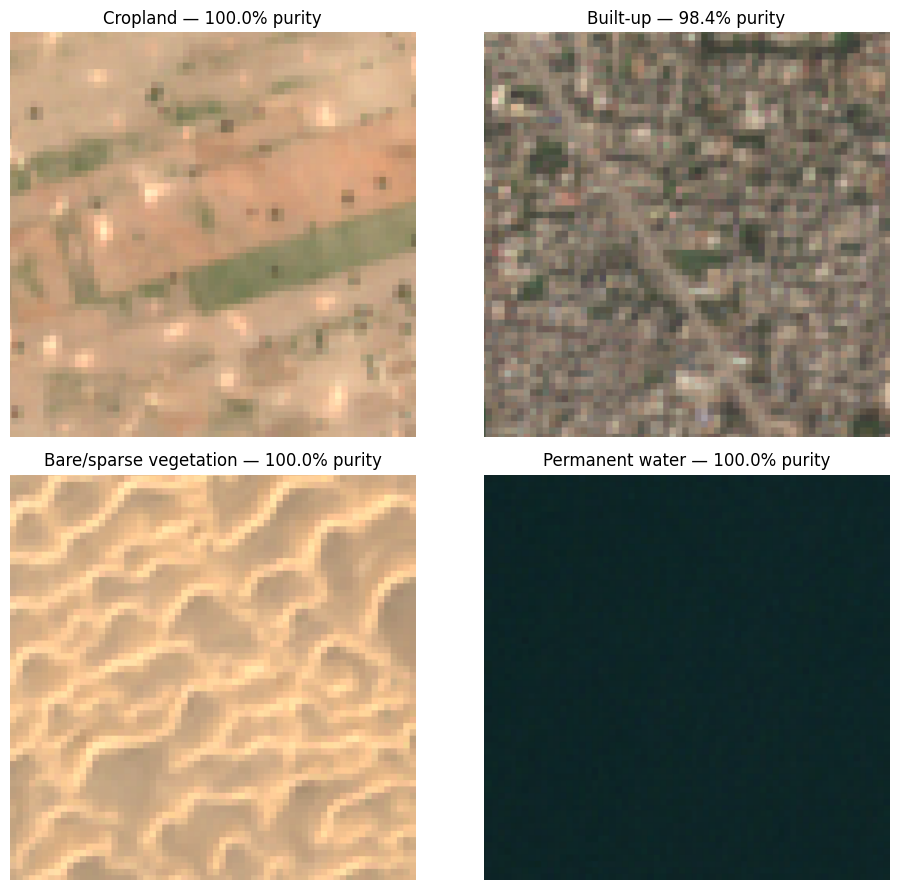

In [ ]:
# Best candidates from our WorldCover purity evaluation
test_points = [
    ("Cropland", 25.818365, 68.310963, 100.0),
    ("Built-up", 32.492847, 74.503949, 98.4),
    ("Bare/sparse vegetation", 28.381258, 63.290279, 100.0),
    ("Permanent water", 34.152036, 72.802540, 100.0),
]

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
axes = axes.flatten()

for ax, (class_name, lat, lon, purity) in zip(axes, test_points):
    point = ee.Geometry.Point([lon, lat])

    image = (
        sentinel
        .filterBounds(point)
        .filterDate("2021-01-01", "2022-01-01")
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20))
        .sort("CLOUDY_PIXEL_PERCENTAGE")
        .first()
    )

    region = point.buffer(320).bounds()

    rgb = image.select(["B4", "B3", "B2"]).visualize(
        min=0, max=3000, gamma=1.2
    )

    url = rgb.getThumbURL({
        "region": region,
        "dimensions": "256x256",
        "format": "png"
    })

    response = requests.get(url, timeout=60)
    response.raise_for_status()

    patch = np.array(
        Image.open(BytesIO(response.content)).convert("RGB")
    )

    ax.imshow(patch)
    ax.set_title(f"{class_name} — {purity}% purity")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
test_points = [
    ("Cropland", 25.818365, 68.310963, 100.0),
    ("Built-up", 32.492847, 74.503949, 98.4),
    ("Bare/sparse vegetation", 28.381258, 63.290279, 100.0),
    ("Permanent water", 34.152036, 72.802540, 100.0),
]

image_stats = []
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, (class_name, lat, lon, purity) in zip(axes, test_points):
    point = ee.Geometry.Point([lon, lat])

    image = (
        sentinel
        .filterBounds(point)
        .filterDate("2021-01-01", "2022-01-01")
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20))
        .sort("CLOUDY_PIXEL_PERCENTAGE")
        .first()
    )

    # Request a larger preview of the same 640 m patch
    region = point.buffer(320).bounds()

    rgb = image.select(["B4", "B3", "B2"]).visualize(
        min=0, max=3000, gamma=1.2
    )

    url = rgb.getThumbURL({
        "region": region,
        "dimensions": "512x512",
        "format": "png"
    })

    response = requests.get(url, timeout=60)
    response.raise_for_status()

    patch = np.asarray(
        Image.open(BytesIO(response.content)).convert("RGB")
    )

    # Basic image statistics
    brightness = patch.mean()
    contrast = patch.std()
    channel_means = patch.mean(axis=(0, 1))

    image_stats.append({
        "Class": class_name,
        "WorldCover purity (%)": purity,
        "Mean brightness (0-255)": round(float(brightness), 1),
        "Pixel variation (std)": round(float(contrast), 1),
        "Red mean": round(float(channel_means[0]), 1),
        "Green mean": round(float(channel_means[1]), 1),
        "Blue mean": round(float(channel_means[2]), 1)
    })

    ax.imshow(patch)
    ax.set_title(f"{class_name} | {purity}% purity")
    ax.axis("off")

plt.tight_layout()
plt.show()

stats_df = pd.DataFrame(image_stats)
display(stats_df)

In [ ]:
test_points = [
    ("Cropland", 25.818365, 68.310963, 40),
    ("Built-up", 32.492847, 74.503949, 50),
    ("Bare/sparse vegetation", 28.381258, 63.290279, 60),
    ("Permanent water", 34.152036, 72.802540, 80),
]

index_results = []

for class_name, lat, lon, class_id in test_points:
    point = ee.Geometry.Point([lon, lat])
    region = point.buffer(320).bounds()

    image = (
        sentinel
        .filterBounds(point)
        .filterDate("2021-01-01", "2022-01-01")
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20))
        .sort("CLOUDY_PIXEL_PERCENTAGE")
        .first()
    )

    # Calculate indices from Sentinel-2 surface reflectance bands.
    ndvi = image.normalizedDifference([
        "B8", "B4"
    ]).rename("NDVI")

    # Normalized Difference Water Index (McFeeters)
    ndwi = image.normalizedDifference([
        "B3", "B8"
    ]).rename("NDWI")

    indices = ndvi.addBands(ndwi)

    stats = indices.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=region,
        scale=10,
        maxPixels=10000,
        tileScale=2
    ).getInfo()

    index_results.append({
        "Class": class_name,
        "Mean NDVI": round(stats["NDVI"], 3)
            if stats.get("NDVI") is not None else None,
        "Mean NDWI": round(stats["NDWI"], 3)
            if stats.get("NDWI") is not None else None
    })

display(pd.DataFrame(index_results))

,Class,Mean NDVI,Mean NDWI
0,Cropland,0.176,-0.282
1,Built-up,0.162,-0.212
2,Bare/sparse vegetation,0.066,-0.187
3,Permanent water,-0.125,0.639


In [ ]:

def mask_sentinel_clouds(image):
    scl = image.select("SCL")

    # Exclude defective pixels, shadows, clouds, cirrus, and snow
    clear_mask = (
        scl.neq(0)   # No data
        .And(scl.neq(1))   # Saturated/defective pixels
        .And(scl.neq(3))   # Cloud shadows
        .And(scl.neq(8))   # Medium-probability clouds
        .And(scl.neq(9))   # High-probability clouds
        .And(scl.neq(10))  # Thin cirrus
        .And(scl.neq(11))  # Snow/ice
    )

    return image.updateMask(clear_mask)


In [ ]:

sentinel_clean = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterDate("2021-01-01", "2022-01-01")
    .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 30))
    .map(mask_sentinel_clouds)
)

print("Cloud-masked Sentinel-2 collection created.")
print("Number of scenes:", sentinel_clean.size().getInfo())


Cloud-masked Sentinel-2 collection created.
Number of scenes: 1686106


In [ ]:

sentinel_pakistan = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(pakistan_geometry)
    .filterDate("2021-01-01", "2022-01-01")
    .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 30))
    .map(mask_sentinel_clouds)
)

print("Pakistan scenes:", sentinel_pakistan.size().getInfo())


Pakistan scenes: 12229


In [ ]:

# Keep candidates with at least 70% WorldCover purity
accepted_candidates = purity_df[purity_df["Purity (%)"] >= 70].copy()

# Count accepted candidates in each class
print("Accepted candidates:", len(accepted_candidates))
display(
    accepted_candidates.groupby("Class")
    .size()
    .reset_index(name="Accepted candidates")
)


Accepted candidates: 45


,Class,Accepted candidates
0,Bare_Sparse_Vegetation,15
1,Built_Up,7
2,Cropland,12
3,Permanent_Water,6
4,Tree_Cover,5


## 10. Initial 64x64 Dataset Generation

### 10.1 Export Sentinel-2 64x64 Images for Single Best Locations

In [ ]:
# Folder for our initial test images
output_dir = "/content/landcover_dataset"
os.makedirs(output_dir, exist_ok=True)

# One highest-purity candidate per class
sample_candidates = (
    accepted_candidates
    .sort_values("Purity (%)", ascending=False)
    .groupby("Class")
    .head(1)
)

extraction_results = []

for _, row in sample_candidates.iterrows():
    class_name = row["Class"]
    lat = float(row["Latitude"])
    lon = float(row["Longitude"])

    print(f"Extracting: {class_name}")

    point = ee.Geometry.Point([lon, lat])
    region = point.buffer(320).bounds()

    # Build a cloud-masked composite for this location
    image = (
        sentinel_pakistan
        .filterBounds(region)
        .filterDate("2021-01-01", "2022-01-01")
        .median()
        .select(["B4", "B3", "B2"])
    )

    # Convert reflectance to a consistent RGB display
    rgb = image.visualize(
        bands=["B4", "B3", "B2"],
        min=0,
        max=3000,
        gamma=1.2,
    )

    # Download the small image thumbnail
    url = rgb.getThumbURL({
        "region": region,
        "dimensions": "64x64",
        "format": "png"
    })

    response = requests.get(url, timeout=60)
    response.raise_for_status()

    img = Image.open(BytesIO(response.content)).convert("RGB")

    filename = f"{class_name}.png"
    filepath = os.path.join(output_dir, filename)
    img.save(filepath)

    extraction_results.append({
        "Class": class_name,
        "Purity (%)": row["Purity (%)"],
        "Image size": img.size,
        "File": filepath
    })

print("\nExtraction summary:")
display(pd.DataFrame(extraction_results))

Extracting: Bare_Sparse_Vegetation
Extracting: Permanent_Water
Extracting: Cropland
Extracting: Built_Up
Extracting: Tree_Cover

Extraction summary:


,Class,Purity (%),Image size,File
0,Bare_Sparse_Vegetation,100.0,"(64, 64)",/content/landcover_dataset/Bare_Sparse_Vegetat...
1,Permanent_Water,100.0,"(64, 64)",/content/landcover_dataset/Permanent_Water.png
2,Cropland,100.0,"(64, 64)",/content/landcover_dataset/Cropland.png
3,Built_Up,98.4,"(64, 64)",/content/landcover_dataset/Built_Up.png
4,Tree_Cover,93.0,"(64, 64)",/content/landcover_dataset/Tree_Cover.png


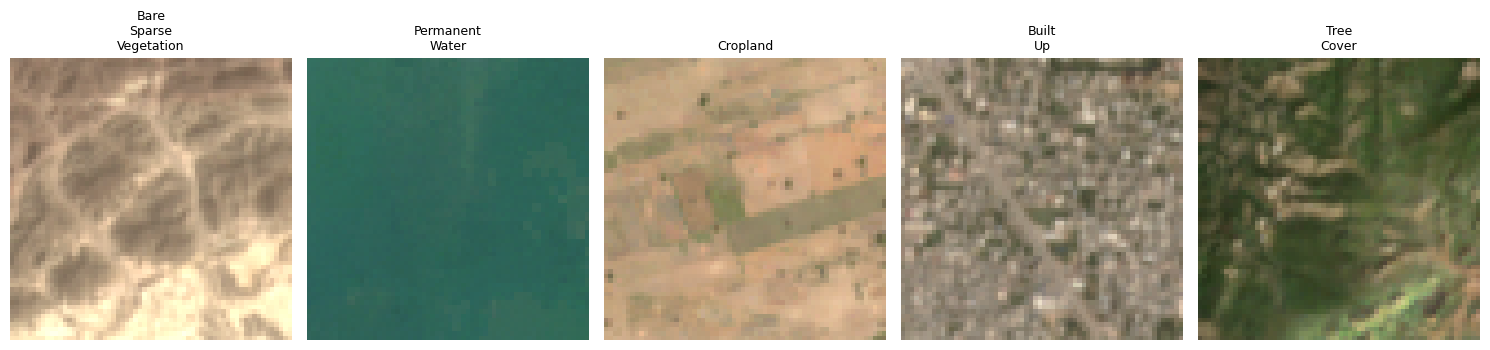

In [ ]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(sample_candidates), figsize=(15, 4))

for ax, (_, row) in zip(axes, sample_candidates.iterrows()):
    path = os.path.join(output_dir, f"{row['Class']}.png")
    img = Image.open(path)

    ax.imshow(img)
    ax.set_title(row["Class"].replace("_", "\n"), fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()



## 11. Expansion and Regional Top-Up Sampling

### 11.1 Generating Nationwide Candidates for Target Classes

In [ ]:

# Generate a larger candidate pool
candidate_count_per_class = 1000

large_candidates = filtered_worldcover.stratifiedSample(
    numPoints=candidate_count_per_class,
    classBand="Map",
    region=pakistan_geometry,
    scale=100,
    classValues=target_classes,
    classPoints=[candidate_count_per_class] * len(target_classes),
    seed=2026,
    geometries=True,
    tileScale=4
)

print("Candidate locations:", large_candidates.size().getInfo())


Candidate locations: 5000


In [ ]:

# Convert candidate points into 640 m x 640 m patches
large_candidate_features = large_candidates.getInfo()["features"]

large_patch_features = []

for feature in large_candidate_features:
    class_id = int(feature["properties"]["Map"])
    lon, lat = feature["geometry"]["coordinates"]

    region = ee.Geometry.Point([lon, lat]).buffer(320).bounds()

    large_patch_features.append(
        ee.Feature(region, {
            "class_id": class_id,
            "longitude": lon,
            "latitude": lat
        })
    )

print("Prepared patches:", len(large_patch_features))


Prepared patches: 5000


In [ ]:

import pandas as pd

batch_size = 100
purity_rows = []

worldcover_image = (
    ee.ImageCollection("ESA/WorldCover/v200")
    .first()
    .select("Map")
)

for start in range(0, len(large_patch_features), batch_size):
    batch_features = large_patch_features[start:start + batch_size]
    batch = ee.FeatureCollection(batch_features)

    results = worldcover_image.reduceRegions(
        collection=batch,
        reducer=ee.Reducer.frequencyHistogram(),
        scale=10,
        tileScale=4
    ).getInfo()["features"]

    for result in results:
        props = result["properties"]
        class_id = int(props["class_id"])
        histogram = props.get("histogram", {})

        total_pixels = sum(histogram.values())
        target_pixels = histogram.get(str(class_id), 0)

        purity = (
            100 * target_pixels / total_pixels
            if total_pixels > 0 else 0
        )

        purity_rows.append({
            "class_id": class_id,
            "Class": CLASS_NAMES[class_id],
            "Latitude": props["latitude"],
            "Longitude": props["longitude"],
            "Purity (%)": round(purity, 1)
        })

    completed = len(purity_rows)
    print(f"Processed {completed}/{len(large_patch_features)} patches")

large_purity_df = pd.DataFrame(purity_rows)

print("\nPurity calculation complete.")
print("Total evaluated:", len(large_purity_df))


Processed 100/5000 patches
Processed 200/5000 patches
Processed 300/5000 patches
Processed 400/5000 patches
Processed 500/5000 patches
Processed 600/5000 patches
Processed 700/5000 patches
Processed 800/5000 patches
Processed 900/5000 patches
Processed 1000/5000 patches
Processed 1100/5000 patches
Processed 1200/5000 patches
Processed 1300/5000 patches
Processed 1400/5000 patches
Processed 1500/5000 patches
Processed 1600/5000 patches
Processed 1700/5000 patches
Processed 1800/5000 patches
Processed 1900/5000 patches
Processed 2000/5000 patches
Processed 2100/5000 patches
Processed 2200/5000 patches
Processed 2300/5000 patches
Processed 2400/5000 patches
Processed 2500/5000 patches
Processed 2600/5000 patches
Processed 2700/5000 patches
Processed 2800/5000 patches
Processed 2900/5000 patches
Processed 3000/5000 patches
Processed 3100/5000 patches
Processed 3200/5000 patches
Processed 3300/5000 patches
Processed 3400/5000 patches
Processed 3500/5000 patches
Processed 3600/5000 patches
P

In [ ]:

# Keep patches meeting our fixed 70% purity threshold
accepted_large_df = large_purity_df[
    large_purity_df["Purity (%)"] >= 70
].copy()

# Count accepted candidates in each class
class_counts = (
    accepted_large_df.groupby("Class")
    .size()
    .reindex(CLASS_NAMES.values(), fill_value=0)
    .reset_index(name="Accepted candidates")
)

print("Total accepted:", len(accepted_large_df))
print("\nAccepted candidates by class:")
display(class_counts)

print("\nCandidates still needed to reach 500 per class:")
class_counts["Needed"] = (
    500 - class_counts["Accepted candidates"]
).clip(lower=0)
display(class_counts)


Total accepted: 2471

Accepted candidates by class:


,Class,Accepted candidates
0,Tree_Cover,284
1,Cropland,710
2,Built_Up,206
3,Bare_Sparse_Vegetation,871
4,Permanent_Water,400



Candidates still needed to reach 500 per class:


,Class,Accepted candidates,Needed
0,Tree_Cover,284,216
1,Cropland,710,0
2,Built_Up,206,294
3,Bare_Sparse_Vegetation,871,0
4,Permanent_Water,400,100


In [ ]:

extra_classes = [10, 50, 80]
points_per_batch = 200
number_of_batches = 5

extra_candidate_features = []

for batch_num in range(number_of_batches):
    print(f"Sampling batch {batch_num + 1}/{number_of_batches}...")

    batch_candidates = filtered_worldcover.stratifiedSample(
        numPoints=points_per_batch,
        classBand="Map",
        region=pakistan_geometry,
        scale=100,
        classValues=extra_classes,
        classPoints=[points_per_batch] * len(extra_classes),
        seed=3000 + batch_num,
        geometries=True,
        tileScale=8
    )

    features = batch_candidates.getInfo()["features"]
    extra_candidate_features.extend(features)

    print("Candidates collected so far:", len(extra_candidate_features))

print("Total additional candidates:", len(extra_candidate_features))


Sampling batch 1/5...


NameError: name 'filtered_worldcover' is not defined

In [ ]:

# Summarize the geographic spread of accepted candidates
accepted_large_df["Latitude"] = pd.to_numeric(
    accepted_large_df["Latitude"]
)
accepted_large_df["Longitude"] = pd.to_numeric(
    accepted_large_df["Longitude"]
)

geographic_summary = (
    accepted_large_df.groupby("Class")
    .agg(
        Count=("Class", "size"),
        Min_Latitude=("Latitude", "min"),
        Max_Latitude=("Latitude", "max"),
        Min_Longitude=("Longitude", "min"),
        Max_Longitude=("Longitude", "max")
    )
    .reset_index()
)

display(geographic_summary)


,Class,Count,Min_Latitude,Max_Latitude,Min_Longitude,Max_Longitude
0,Bare_Sparse_Vegetation,871,24.167261,36.789489,60.950168,73.978434
1,Built_Up,206,24.735895,34.609278,66.967084,75.169601
2,Cropland,710,24.244516,34.811399,64.827297,75.207330
3,Permanent_Water,400,23.861834,35.364761,62.716256,74.466220
4,Tree_Cover,284,25.194934,35.771698,68.294794,74.034130


In [ ]:

# Sample additional candidates from smaller regions.
# Run this cell instead of the earlier nationwide extra_candidates code.

extra_classes = [10, 50, 80]

# Each rectangle: (name, west longitude, south latitude,
#                  east longitude, north latitude)
sampling_regions = [
    ("Northern Pakistan", 70.0, 33.0, 74.5, 36.5),
    ("Upper Punjab",      71.0, 29.5, 74.5, 33.0),
    ("Central Punjab",    71.0, 27.5, 74.5, 30.5),
    ("Lower Punjab",      68.0, 26.0, 72.5, 30.0),
    ("Sindh",              66.0, 23.5, 70.5, 28.0),
]

extra_candidate_features = []

for region_name, west, south, east, north in sampling_regions:
    print(f"Sampling: {region_name}")

    region = ee.Geometry.Rectangle(
        [west, south, east, north],
        proj="EPSG:4326",
        geodesic=False
    )

    regional_candidates = filtered_worldcover.stratifiedSample(
        numPoints=100,
        classBand="Map",
        region=region,
        scale=100,
        classValues=extra_classes,
        classPoints=[100, 100, 100],
        seed=2026 + len(extra_candidate_features),
        geometries=True,
        tileScale=4
    )

    features = regional_candidates.getInfo()["features"]

    for feature in features:
        feature["properties"]["sampling_region"] = region_name

    extra_candidate_features.extend(features)
    print(f"  Retrieved {len(features)} candidates")

print("Total additional candidates:", len(extra_candidate_features))


Sampling: Northern Pakistan
  Retrieved 500 candidates
Sampling: Upper Punjab
  Retrieved 500 candidates
Sampling: Central Punjab
  Retrieved 500 candidates
Sampling: Lower Punjab
  Retrieved 500 candidates
Sampling: Sindh
  Retrieved 500 candidates
Total additional candidates: 2500


In [ ]:
print(Counter(
    int(feature["properties"]["Map"])
    for feature in extra_candidate_features
))

Counter({10: 500, 40: 500, 50: 500, 60: 500, 80: 500})


In [ ]:

import ee
import pandas as pd
from math import radians, sin, cos, sqrt, atan2

# Existing candidate centers
existing_coords = set(
    zip(
        large_purity_df["Latitude"].round(5),
        large_purity_df["Longitude"].round(5)
    )
)

# Convert new candidates to a dataframe
extra_rows = []

for feature in extra_candidate_features:
    props = feature["properties"]
    lon, lat = feature["geometry"]["coordinates"]

    # Skip points outside Pakistan
    point = ee.Geometry.Point([lon, lat])
    inside_pakistan = pakistan_geometry.contains(
        point, ee.ErrorMargin(100)
    ).getInfo()

    if not inside_pakistan:
        continue

    # Skip duplicate or nearly identical centers
    coord_key = (round(lat, 5), round(lon, 5))
    if coord_key in existing_coords:
        continue

    extra_rows.append({
        "class_id": int(props["Map"]),
        "Class": CLASS_NAMES[int(props["Map"])],
        "Latitude": lat,
        "Longitude": lon,
        "sampling_region": props.get("sampling_region", "")
    })

    existing_coords.add(coord_key)

extra_candidates_df = pd.DataFrame(extra_rows)

print("New candidate locations inside Pakistan:",
      len(extra_candidates_df))
print("\nCandidates by class:")
print(extra_candidates_df["Class"].value_counts())


New candidate locations inside Pakistan: 1594

Candidates by class:
Class
Built_Up                  351
Tree_Cover                350
Cropland                  310
Permanent_Water           299
Bare_Sparse_Vegetation    284
Name: count, dtype: int64


In [ ]:

# Calculate WorldCover purity for additional candidates in batches.

batch_size = 100
extra_purity_rows = []

for start in range(0, len(extra_candidates_df), batch_size):
    batch_df = extra_candidates_df.iloc[start:start + batch_size]

    patch_features = []

    for _, row in batch_df.iterrows():
        region = (
            ee.Geometry.Point([
                row["Longitude"], row["Latitude"]
            ])
            .buffer(320)
            .bounds()
        )

        patch_features.append(
            ee.Feature(region, {
                "class_id": int(row["class_id"]),
                "Class": row["Class"],
                "Latitude": row["Latitude"],
                "Longitude": row["Longitude"],
                "sampling_region": row["sampling_region"]
            })
        )

    results = worldcover_image.reduceRegions(
        collection=ee.FeatureCollection(patch_features),
        reducer=ee.Reducer.frequencyHistogram(),
        scale=10,
        tileScale=4
    ).getInfo()["features"]

    for result in results:
        props = result["properties"]
        class_id = int(props["class_id"])
        histogram = props.get("histogram", {})

        total_pixels = sum(histogram.values())
        target_pixels = histogram.get(str(class_id), 0)
        purity = (
            100 * target_pixels / total_pixels
            if total_pixels > 0 else 0
        )

        extra_purity_rows.append({
            "class_id": class_id,
            "Class": props["Class"],
            "Latitude": props["Latitude"],
            "Longitude": props["Longitude"],
            "Purity (%)": round(purity, 1),
            "sampling_region": props["sampling_region"]
        })

    print(
        f"Processed {min(start + batch_size, len(extra_candidates_df))}"
        f"/{len(extra_candidates_df)} candidates"
    )

extra_purity_df = pd.DataFrame(extra_purity_rows)

accepted_extra_df = extra_purity_df[
    extra_purity_df["Purity (%)"] >= 70
].copy()

print("\nAdditional candidates passing 70% purity:",
      len(accepted_extra_df))
print("\nAccepted candidates by class:")
print(accepted_extra_df["Class"].value_counts())


Processed 100/1594 candidates
Processed 200/1594 candidates
Processed 300/1594 candidates
Processed 400/1594 candidates
Processed 500/1594 candidates
Processed 600/1594 candidates
Processed 700/1594 candidates
Processed 800/1594 candidates
Processed 900/1594 candidates
Processed 1000/1594 candidates
Processed 1100/1594 candidates
Processed 1200/1594 candidates
Processed 1300/1594 candidates
Processed 1400/1594 candidates
Processed 1500/1594 candidates
Processed 1594/1594 candidates

Additional candidates passing 70% purity: 629

Accepted candidates by class:
Class
Cropland                  232
Bare_Sparse_Vegetation    187
Built_Up                   86
Permanent_Water            77
Tree_Cover                 47
Name: count, dtype: int64


In [ ]:

# Combine original and additional accepted candidates.

original = accepted_large_df.copy()
additional = accepted_extra_df.copy()

# Ensure consistent column names and types.
original["class_id"] = original["class_id"].astype(int)
additional["class_id"] = additional["class_id"].astype(int)

combined_candidates_df = pd.concat(
    [original, additional],
    ignore_index=True
)

# Remove duplicate coordinates.
combined_candidates_df["coord_key"] = list(zip(
    combined_candidates_df["Latitude"].round(5),
    combined_candidates_df["Longitude"].round(5)
))

combined_candidates_df = combined_candidates_df.drop_duplicates(
    subset="coord_key"
).drop(columns="coord_key")

print("Combined unique candidates:", len(combined_candidates_df))
print("\nCandidates per class:")
print(combined_candidates_df["Class"].value_counts())


Combined unique candidates: 3100

Candidates per class:
Class
Bare_Sparse_Vegetation    1058
Cropland                   942
Permanent_Water            477
Tree_Cover                 331
Built_Up                   292
Name: count, dtype: int64


In [ ]:

# Restrict sampling to classes that are still underrepresented.

needed_classes = [10, 50, 80]

needed_mask = (
    worldcover_image.eq(10)
    .Or(worldcover_image.eq(50))
    .Or(worldcover_image.eq(80))
)

needed_worldcover = worldcover_image.updateMask(needed_mask)

# Sample 150 candidates per needed class from each region.
# The total requested is 2,250 candidates, allowing for purity failures.

extra_sampling_regions = [
    ("Northern Pakistan", 70.0, 33.0, 74.5, 36.5),
    ("Upper Punjab",      71.0, 29.5, 74.5, 33.0),
    ("Central Punjab",    71.0, 27.5, 74.5, 30.5),
    ("Lower Punjab",      68.0, 26.0, 72.5, 30.0),
    ("Sindh",              66.0, 23.5, 70.5, 28.0),
]

topup_candidate_features = []

for i, (region_name, west, south, east, north) in enumerate(
    extra_sampling_regions
):
    print(f"Sampling: {region_name}")

    region = ee.Geometry.Rectangle(
        [west, south, east, north],
        proj="EPSG:4326",
        geodesic=False
    )

    candidates = needed_worldcover.stratifiedSample(
        numPoints=150,
        classBand="Map",
        region=region,
        scale=100,
        classValues=needed_classes,
        classPoints=[150, 150, 150],
        seed=5000 + i,
        geometries=True,
        tileScale=4
    )

    features = candidates.getInfo()["features"]

    for feature in features:
        feature["properties"]["sampling_region"] = region_name

    topup_candidate_features.extend(features)
    print(f"  Retrieved {len(features)} candidates")

print("Total top-up candidates:", len(topup_candidate_features))


Sampling: Northern Pakistan
  Retrieved 450 candidates
Sampling: Upper Punjab
  Retrieved 450 candidates
Sampling: Central Punjab
  Retrieved 450 candidates
Sampling: Lower Punjab
  Retrieved 450 candidates
Sampling: Sindh
  Retrieved 450 candidates
Total top-up candidates: 2250


In [ ]:

# Filter top-up candidates to Pakistan and remove existing coordinates.

topup_features = []

for feature in topup_candidate_features:
    props = feature["properties"]
    lon, lat = feature["geometry"]["coordinates"]

    topup_features.append(
        ee.Feature(
            ee.Geometry.Point([lon, lat]),
            {
                "class_id": int(props["Map"]),
                "Class": CLASS_NAMES[int(props["Map"])],
                "Latitude": lat,
                "Longitude": lon,
                "sampling_region": props.get("sampling_region", "")
            }
        )
    )

# Filter on the Earth Engine server.
topup_inside = (
    ee.FeatureCollection(topup_features)
    .filterBounds(pakistan_geometry)
    .getInfo()["features"]
)

# Remove duplicates against the existing combined dataset.
existing_coords = set(
    zip(
        combined_candidates_df["Latitude"].round(5),
        combined_candidates_df["Longitude"].round(5)
    )
)

topup_rows = []

for feature in topup_inside:
    props = feature["properties"]
    lat = float(props["Latitude"])
    lon = float(props["Longitude"])
    key = (round(lat, 5), round(lon, 5))

    if key in existing_coords:
        continue

    existing_coords.add(key)
    topup_rows.append(props)

topup_candidates_df = pd.DataFrame(topup_rows)

print("New unique candidates:", len(topup_candidates_df))
print("\nCandidates by class:")
print(topup_candidates_df["Class"].value_counts())


New unique candidates: 1782

Candidates by class:
Class
Built_Up           638
Tree_Cover         623
Permanent_Water    521
Name: count, dtype: int64


In [ ]:

# Calculate purity for the new top-up candidates.

batch_size = 100
topup_purity_rows = []

for start in range(0, len(topup_candidates_df), batch_size):
    batch_df = topup_candidates_df.iloc[start:start + batch_size]
    patch_features = []

    for _, row in batch_df.iterrows():
        region = (
            ee.Geometry.Point([
                row["Longitude"], row["Latitude"]
            ])
            .buffer(320)
            .bounds()
        )

        patch_features.append(
            ee.Feature(region, {
                "class_id": int(row["class_id"]),
                "Class": row["Class"],
                "Latitude": row["Latitude"],
                "Longitude": row["Longitude"],
                "sampling_region": row["sampling_region"]
            })
        )

    results = worldcover_image.reduceRegions(
        collection=ee.FeatureCollection(patch_features),
        reducer=ee.Reducer.frequencyHistogram(),
        scale=10,
        tileScale=4
    ).getInfo()["features"]

    for result in results:
        props = result["properties"]
        class_id = int(props["class_id"])
        histogram = props.get("histogram", {})

        total_pixels = sum(histogram.values())
        target_pixels = histogram.get(str(class_id), 0)
        purity = (
            100 * target_pixels / total_pixels
            if total_pixels > 0 else 0
        )

        topup_purity_rows.append({
            "class_id": class_id,
            "Class": props["Class"],
            "Latitude": props["Latitude"],
            "Longitude": props["Longitude"],
            "Purity (%)": round(purity, 1),
            "sampling_region": props["sampling_region"]
        })

    print(
        f"Processed {min(start + batch_size, len(topup_candidates_df))}"
        f"/{len(topup_candidates_df)} candidates"
    )

topup_purity_df = pd.DataFrame(topup_purity_rows)

accepted_topup_df = topup_purity_df[
    topup_purity_df["Purity (%)"] >= 70
].copy()

print("\nTop-up candidates passing purity:", len(accepted_topup_df))
print("\nAccepted candidates by class:")
print(accepted_topup_df["Class"].value_counts())


Processed 100/1782 candidates
Processed 200/1782 candidates
Processed 300/1782 candidates
Processed 400/1782 candidates
Processed 500/1782 candidates
Processed 600/1782 candidates
Processed 700/1782 candidates
Processed 800/1782 candidates
Processed 900/1782 candidates
Processed 1000/1782 candidates
Processed 1100/1782 candidates
Processed 1200/1782 candidates
Processed 1300/1782 candidates
Processed 1400/1782 candidates
Processed 1500/1782 candidates
Processed 1600/1782 candidates
Processed 1700/1782 candidates
Processed 1782/1782 candidates

Top-up candidates passing purity: 373

Accepted candidates by class:
Class
Permanent_Water    149
Built_Up           117
Tree_Cover         107
Name: count, dtype: int64


In [ ]:

# Combine all accepted candidate batches.

combined_candidates_df = pd.concat(
    [
        accepted_large_df,
        accepted_extra_df,
        accepted_topup_df
    ],
    ignore_index=True
)

# Remove duplicate coordinates.
combined_candidates_df["Latitude"] = pd.to_numeric(
    combined_candidates_df["Latitude"]
)
combined_candidates_df["Longitude"] = pd.to_numeric(
    combined_candidates_df["Longitude"]
)

combined_candidates_df["coord_key"] = list(zip(
    combined_candidates_df["Latitude"].round(5),
    combined_candidates_df["Longitude"].round(5)
))

combined_candidates_df = combined_candidates_df.drop_duplicates(
    subset="coord_key"
).drop(columns="coord_key")

print("Combined unique accepted candidates:",
      len(combined_candidates_df))

print("\nAccepted candidates per class:")
print(combined_candidates_df["Class"].value_counts())


Combined unique accepted candidates: 3473

Accepted candidates per class:
Class
Bare_Sparse_Vegetation    1058
Cropland                   942
Permanent_Water            626
Tree_Cover                 438
Built_Up                   409
Name: count, dtype: int64


## 12. Spatial Dissimilarity Filtering (640m Spacing)

### 12.1 Applying Spatially Retained Haversine Distance Filters

In [ ]:

import numpy as np
import pandas as pd
from sklearn.neighbors import BallTree

# Work in radians for the haversine distance calculation.
EARTH_RADIUS_M = 6_371_000
MIN_DISTANCE_M = 640

spatially_filtered_parts = []

for class_name, group in combined_candidates_df.groupby("Class"):
    group = group.copy().reset_index(drop=True)

    coords_rad = np.radians(
        group[["Latitude", "Longitude"]].to_numpy()
    )

    # Greedily retain candidates at least 640 m from
    # previously retained candidates in this class.
    tree = BallTree(coords_rad, metric="haversine")
    retained_indices = []
    retained_coords = []

    # Process high-purity patches first.
    order = group.sort_values(
        "Purity (%)", ascending=False
    ).index.tolist()

    for idx in order:
        point = coords_rad[idx]

        if not retained_coords:
            retained_indices.append(idx)
            retained_coords.append(point)
            continue

        retained_array = np.array(retained_coords)
        distances = (
            np.arccos(
                np.clip(
                    np.sin(point[0]) * np.sin(retained_array[:, 0])
                    + np.cos(point[0]) * np.cos(retained_array[:, 0])
                    * np.cos(retained_array[:, 1] - point[1]),
                    -1, 1
                )
            ) * EARTH_RADIUS_M
        )

        if distances.min() >= MIN_DISTANCE_M:
            retained_indices.append(idx)
            retained_coords.append(point)

    filtered_group = group.loc[retained_indices].copy()
    spatially_filtered_parts.append(filtered_group)

    print(
        f"{class_name}: {len(group)} candidates -> "
        f"{len(filtered_group)} after spacing"
    )

spatially_filtered_df = pd.concat(
    spatially_filtered_parts, ignore_index=True
)

print("\nTotal after spacing:", len(spatially_filtered_df))
print("\nCounts by class:")
print(spatially_filtered_df["Class"].value_counts())


Bare_Sparse_Vegetation: 1058 candidates -> 1058 after spacing
Built_Up: 409 candidates -> 376 after spacing
Cropland: 942 candidates -> 940 after spacing
Permanent_Water: 626 candidates -> 575 after spacing
Tree_Cover: 438 candidates -> 422 after spacing

Total after spacing: 3371

Counts by class:
Class
Bare_Sparse_Vegetation    1058
Cropland                   940
Permanent_Water            575
Tree_Cover                 422
Built_Up                   376
Name: count, dtype: int64


In [ ]:

import numpy as np
from sklearn.neighbors import BallTree

EARTH_RADIUS_M = 6_371_000
MIN_DISTANCE_M = 640

coords_rad = np.radians(
    spatially_filtered_df[["Latitude", "Longitude"]].to_numpy()
)

tree = BallTree(coords_rad, metric="haversine")

# Find candidate pairs within 640 metres.
pairs = tree.query_radius(
    coords_rad,
    r=MIN_DISTANCE_M / EARTH_RADIUS_M
)

cross_class_pairs = []

classes = spatially_filtered_df["Class"].to_numpy()

for i, neighbors in enumerate(pairs):
    for j in neighbors:
        if j > i and classes[i] != classes[j]:
            cross_class_pairs.append((i, j))

print("Cross-class pairs closer than 640 m:",
      len(cross_class_pairs))


Cross-class pairs closer than 640 m: 0


In [ ]:

# Sample more candidates only for the two classes still below 500.

needed_classes = [10, 50]  # Tree Cover, Built-up

needed_mask = worldcover_image.eq(10).Or(worldcover_image.eq(50))
needed_worldcover = worldcover_image.updateMask(needed_mask)

# Smaller regional areas to avoid nationwide timeouts.
target_regions = [
    ("Northern Pakistan", 70.0, 33.0, 74.5, 36.5),
    ("Upper Punjab", 71.0, 29.5, 74.5, 33.0),
    ("Central Punjab", 71.0, 27.5, 74.5, 30.5),
    ("Lower Punjab", 68.0, 26.0, 72.5, 30.0),
    ("Sindh", 66.0, 23.5, 70.5, 28.0),
]

final_topup_features = []

for i, (name, west, south, east, north) in enumerate(target_regions):
    print("Sampling:", name)

    region = ee.Geometry.Rectangle(
        [west, south, east, north],
        proj="EPSG:4326",
        geodesic=False
    )

    candidates = needed_worldcover.stratifiedSample(
        numPoints=200,
        classBand="Map",
        region=region,
        scale=100,
        classValues=needed_classes,
        classPoints=[200, 200],
        seed=8000 + i,
        geometries=True,
        tileScale=4
    )

    features = candidates.getInfo()["features"]

    for feature in features:
        feature["properties"]["sampling_region"] = name

    final_topup_features.extend(features)
    print("  Retrieved:", len(features))

print("Total new candidates:", len(final_topup_features))


Sampling: Northern Pakistan
  Retrieved: 400
Sampling: Upper Punjab
  Retrieved: 400
Sampling: Central Punjab
  Retrieved: 400
Sampling: Lower Punjab
  Retrieved: 400
Sampling: Sindh
  Retrieved: 400
Total new candidates: 2000


In [ ]:

# Convert the latest candidate features into a dataframe.
final_topup_rows = []

for feature in final_topup_features:
    props = feature["properties"]
    lon, lat = feature["geometry"]["coordinates"]

    final_topup_rows.append({
        "class_id": int(props["Map"]),
        "Class": CLASS_NAMES[int(props["Map"])],
        "Latitude": lat,
        "Longitude": lon,
        "sampling_region": props.get("sampling_region", "")
    })

final_topup_df = pd.DataFrame(final_topup_rows)

# Filter to points inside Pakistan using Earth Engine.
final_topup_ee_features = [
    ee.Feature(
        ee.Geometry.Point([row["Longitude"], row["Latitude"]]),
        row.to_dict()
    )
    for _, row in final_topup_df.iterrows()
]

inside_features = (
    ee.FeatureCollection(final_topup_ee_features)
    .filterBounds(pakistan_geometry)
    .getInfo()["features"]
)

inside_rows = [f["properties"] for f in inside_features]
final_topup_df = pd.DataFrame(inside_rows)

# Remove duplicate coordinates against all existing candidates.
existing_coords = set(zip(
    combined_candidates_df["Latitude"].round(5),
    combined_candidates_df["Longitude"].round(5)
))

# Also include candidates from the two previous top-up batches.
for df in [topup_candidates_df]:
    if not df.empty:
        existing_coords.update(zip(
            df["Latitude"].round(5),
            df["Longitude"].round(5)
        ))

keep_rows = []

for _, row in final_topup_df.iterrows():
    key = (round(float(row["Latitude"]), 5),
           round(float(row["Longitude"]), 5))

    if key not in existing_coords:
        keep_rows.append(row)
        existing_coords.add(key)

final_topup_df = pd.DataFrame(keep_rows).reset_index(drop=True)

print("New unique candidates inside Pakistan:", len(final_topup_df))
print("\nBy class:")
print(final_topup_df["Class"].value_counts())


New unique candidates inside Pakistan: 1677

By class:
Class
Built_Up      860
Tree_Cover    817
Name: count, dtype: int64


In [ ]:

batch_size = 100
final_topup_purity_rows = []

for start in range(0, len(final_topup_df), batch_size):
    batch_df = final_topup_df.iloc[start:start + batch_size]
    patch_features = []

    for _, row in batch_df.iterrows():
        region = (
            ee.Geometry.Point([
                row["Longitude"], row["Latitude"]
            ])
            .buffer(320)
            .bounds()
        )

        patch_features.append(
            ee.Feature(region, {
                "class_id": int(row["class_id"]),
                "Class": row["Class"],
                "Latitude": row["Latitude"],
                "Longitude": row["Longitude"],
                "sampling_region": row["sampling_region"]
            })
        )

    results = worldcover_image.reduceRegions(
        collection=ee.FeatureCollection(patch_features),
        reducer=ee.Reducer.frequencyHistogram(),
        scale=10,
        tileScale=4
    ).getInfo()["features"]

    for result in results:
        props = result["properties"]
        class_id = int(props["class_id"])
        histogram = props.get("histogram", {})

        total_pixels = sum(histogram.values())
        target_pixels = histogram.get(str(class_id), 0)

        purity = (
            100 * target_pixels / total_pixels
            if total_pixels > 0 else 0
        )

        final_topup_purity_rows.append({
            "class_id": class_id,
            "Class": props["Class"],
            "Latitude": props["Latitude"],
            "Longitude": props["Longitude"],
            "Purity (%)": round(purity, 1),
            "sampling_region": props["sampling_region"]
        })

    print(
        f"Processed {min(start + batch_size, len(final_topup_df))}"
        f"/{len(final_topup_df)} candidates"
    )

final_topup_purity_df = pd.DataFrame(final_topup_purity_rows)

accepted_final_topup_df = final_topup_purity_df[
    final_topup_purity_df["Purity (%)"] >= 70
].copy()

print("\nPassing purity threshold:", len(accepted_final_topup_df))
print("\nAccepted candidates by class:")
print(accepted_final_topup_df["Class"].value_counts())


Processed 100/1677 candidates
Processed 200/1677 candidates
Processed 300/1677 candidates
Processed 400/1677 candidates
Processed 500/1677 candidates
Processed 600/1677 candidates
Processed 700/1677 candidates
Processed 800/1677 candidates
Processed 900/1677 candidates
Processed 1000/1677 candidates
Processed 1100/1677 candidates
Processed 1200/1677 candidates
Processed 1300/1677 candidates
Processed 1400/1677 candidates
Processed 1500/1677 candidates
Processed 1600/1677 candidates
Processed 1677/1677 candidates

Passing purity threshold: 332

Accepted candidates by class:
Class
Built_Up      196
Tree_Cover    136
Name: count, dtype: int64


In [ ]:

import numpy as np
from sklearn.neighbors import BallTree

EARTH_RADIUS_M = 6_371_000
MIN_DISTANCE_M = 640

existing_coords_rad = np.radians(
    spatially_filtered_df[["Latitude", "Longitude"]].to_numpy()
)

existing_tree = BallTree(
    existing_coords_rad,
    metric="haversine"
)

new_coords_rad = np.radians(
    accepted_final_topup_df[["Latitude", "Longitude"]].to_numpy()
)

distances, _ = existing_tree.query(
    new_coords_rad,
    k=1,
    return_distance=True
)

accepted_final_topup_df = accepted_final_topup_df.copy()
accepted_final_topup_df["Nearest existing distance (m)"] = (
    distances[:, 0] * EARTH_RADIUS_M
)

spaced_final_topup_df = accepted_final_topup_df[
    accepted_final_topup_df["Nearest existing distance (m)"]
    >= MIN_DISTANCE_M
].copy()

print("New candidates passing spacing:", len(spaced_final_topup_df))
print("\nBy class:")
print(spaced_final_topup_df["Class"].value_counts())


New candidates passing spacing: 299

By class:
Class
Built_Up      174
Tree_Cover    125
Name: count, dtype: int64


In [ ]:

# Add the new spaced candidates to the existing spaced dataset.

final_candidate_pool = pd.concat(
    [
        spatially_filtered_df,
        spaced_final_topup_df.drop(
            columns=["Nearest existing distance (m)"],
            errors="ignore"
        )
    ],
    ignore_index=True
)

print("Total candidate pool:", len(final_candidate_pool))
print("\nCandidates per class:")
print(final_candidate_pool["Class"].value_counts())


Total candidate pool: 3670

Candidates per class:
Class
Bare_Sparse_Vegetation    1058
Cropland                   940
Permanent_Water            575
Built_Up                   550
Tree_Cover                 547
Name: count, dtype: int64


In [ ]:

import numpy as np
import pandas as pd
from sklearn.neighbors import BallTree

EARTH_RADIUS_M = 6_371_000
MIN_DISTANCE_M = 640
TARGET_PER_CLASS = 500

# Prioritize candidates with higher purity.
pool = final_candidate_pool.copy().reset_index(drop=True)
pool["Purity (%)"] = pd.to_numeric(pool["Purity (%)"])

pool = pool.sort_values(
    "Purity (%)",
    ascending=False
).reset_index(drop=True)

selected_indices = []
selected_coords = []
selected_counts = {name: 0 for name in CLASS_NAMES.values()}

for idx, row in pool.iterrows():
    class_name = row["Class"]

    if selected_counts[class_name] >= TARGET_PER_CLASS:
        continue

    point = np.radians(
        [row["Latitude"], row["Longitude"]]
    )

    # Check distance against every already-selected candidate.
    if selected_coords:
        coords = np.array(selected_coords)

        lat1, lon1 = point
        lat2, lon2 = coords[:, 0], coords[:, 1]

        a = (
            np.sin((lat2 - lat1) / 2) ** 2
            + np.cos(lat1) * np.cos(lat2)
            * np.sin((lon2 - lon1) / 2) ** 2
        )

        distances = (
            2 * EARTH_RADIUS_M
            * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
        )

        if distances.min() < MIN_DISTANCE_M:
            continue

    selected_indices.append(idx)
    selected_coords.append(point)
    selected_counts[class_name] += 1

    if all(
        count == TARGET_PER_CLASS
        for count in selected_counts.values()
    ):
        break

final_dataset_df = pool.loc[selected_indices].copy()

print("Selected patches:", len(final_dataset_df))
print("\nSelected patches per class:")
print(final_dataset_df["Class"].value_counts())
print("\nPurity summary:")
print(final_dataset_df["Purity (%)"].describe())


Selected patches: 2500

Selected patches per class:
Class
Bare_Sparse_Vegetation    500
Cropland                  500
Permanent_Water           500
Built_Up                  500
Tree_Cover                500
Name: count, dtype: int64

Purity summary:
count    2500.000000
mean       92.008960
std         8.376619
min        72.100000
25%        85.775000
50%        94.700000
75%       100.000000
max       100.000000
Name: Purity (%), dtype: float64


## 13. Stratified Dataset Splitting & Spatial Grouping

### 13.1 Save Spatially Selected Candidates Metadata

In [ ]:
import os

# Configure the new centralized project structure in Google Drive
PROJECT_ROOT = "/content/drive/MyDrive/Satellite-Land-Cover-Classification"
METADATA_DIR = os.path.join(PROJECT_ROOT, "metadata")
DATASET_DIR = os.path.join(PROJECT_ROOT, "dataset")

os.makedirs(METADATA_DIR, exist_ok=True)
os.makedirs(DATASET_DIR, exist_ok=True)

metadata_path = os.path.join(METADATA_DIR, "selected_candidates.csv")
final_dataset_df.to_csv(metadata_path, index=False)

print("Saved candidate metadata to:", metadata_path)
print("Rows:", len(final_dataset_df))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved candidate metadata to: /content/drive/MyDrive/landcover_project/selected_candidates.csv
Rows: 2500


In [ ]:

import os
import requests
from io import BytesIO
from PIL import Image

TEST_DIR = "/content/landcover_test_batch"
os.makedirs(TEST_DIR, exist_ok=True)

# Test one selected candidate from each class.
test_samples = (
    final_dataset_df
    .groupby("Class", group_keys=False)
    .head(1)
)

for _, row in test_samples.iterrows():
    class_name = row["Class"]
    lon = float(row["Longitude"])
    lat = float(row["Latitude"])

    region = (
        ee.Geometry.Point([lon, lat])
        .buffer(320)
        .bounds()
    )

    # Use the existing cloud-masked Sentinel-2 collection.
    image = (
        sentinel_pakistan
        .filterBounds(region)
        .filterDate("2021-01-01", "2022-01-01")
        .median()
        .select(["B4", "B3", "B2"])
    )

    rgb = image.visualize(
        bands=["B4", "B3", "B2"],
        min=0,
        max=3000,
        gamma=1.2
    )

    url = rgb.getThumbURL({
        "region": region,
        "dimensions": "64x64",
        "format": "png"
    })

    response = requests.get(url, timeout=60)
    response.raise_for_status()

    img = Image.open(BytesIO(response.content)).convert("RGB")

    filename = f"{class_name}.png"
    img.save(os.path.join(TEST_DIR, filename))

    print(
        f"{class_name}: saved {img.size} image "
        f"({len(response.content):,} downloaded bytes)"
    )

print("\nTest batch saved to:", TEST_DIR)


NameError: name 'final_dataset_df' is not defined

In [ ]:
# ============================================
# STEP 1: VERIFY THE SELECTED DATASET
# ============================================

import pandas as pd

# Check that the dataset exists
print("Dataset shape:", final_dataset_df.shape)

# Check required columns
required_columns = [
    "Class",
    "Latitude",
    "Longitude",
    "Purity (%)"
]

missing_columns = [
    col for col in required_columns
    if col not in final_dataset_df.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Check total images and duplicate locations
print("Total selected locations:", len(final_dataset_df))
print("Duplicate coordinates:",
      final_dataset_df.duplicated(
          subset=["Latitude", "Longitude"]
      ).sum())

# Count locations in each class
print("\nLocations per class:")
print(final_dataset_df["Class"].value_counts().sort_index())

# Check purity
print("\nPurity summary:")
print(final_dataset_df["Purity (%)"].describe())

# Check missing values
print("\nMissing values:")
print(final_dataset_df[required_columns].isna().sum())

# Check whether every class has 500 locations
assert len(final_dataset_df) == 2500, "Expected 2,500 locations"
assert (final_dataset_df["Class"].value_counts() == 500).all(), \
    "At least one class does not have exactly 500 locations"

print("\nDataset checks passed!")

Dataset shape: (2500, 6)
Total selected locations: 2500
Duplicate coordinates: 0

Locations per class:
Class
Bare_Sparse_Vegetation    500
Built_Up                  500
Cropland                  500
Permanent_Water           500
Tree_Cover                500
Name: count, dtype: int64

Purity summary:
count    2500.000000
mean       92.008960
std         8.376619
min        72.100000
25%        85.775000
50%        94.700000
75%       100.000000
max       100.000000
Name: Purity (%), dtype: float64

Missing values:
Class         0
Latitude      0
Longitude     0
Purity (%)    0
dtype: int64

Dataset checks passed!


In [ ]:
# ============================================
# STEP 2: CREATE GEOGRAPHIC GROUPS
# ============================================

import numpy as np
from sklearn.cluster import MiniBatchKMeans

# Work on a copy; keep the original unchanged
split_df = final_dataset_df.copy().reset_index(drop=True)

# Approximate conversion to kilometres.
# Longitude distance varies with latitude, so adjust it.
mean_latitude = split_df["Latitude"].mean()

split_df["x_km"] = (
    split_df["Longitude"]
    * 111.32
    * np.cos(np.radians(mean_latitude))
)

split_df["y_km"] = split_df["Latitude"] * 111.32

coordinates = split_df[["x_km", "y_km"]].values

# Create geographic clusters.
# We start with 50 groups and will inspect their sizes.
geo_model = MiniBatchKMeans(
    n_clusters=50,
    random_state=42,
    n_init=10,
    batch_size=256
)

split_df["geo_group"] = geo_model.fit_predict(coordinates)

print("Geographic groups:", split_df["geo_group"].nunique())

print("\nLocations per geographic group:")
print(split_df["geo_group"].value_counts().describe())

print("\nGroup sizes:")
print(split_df["geo_group"].value_counts().sort_index())

Geographic groups: 50

Locations per geographic group:
count     50.000000
mean      50.000000
std       24.221765
min       14.000000
25%       31.250000
50%       44.500000
75%       62.750000
max      120.000000
Name: count, dtype: float64

Group sizes:
geo_group
0      30
1      58
2      38
3      61
4      32
5      95
6      72
7      44
8      33
9      55
10    120
11     65
12     19
13     70
14     29
15     71
16     45
17     62
18     47
19     71
20     14
21     23
22     82
23     31
24     75
25     44
26     17
27     70
28     30
29     63
30     40
31     59
32     14
33     47
34     43
35     54
36     33
37    113
38     53
39     30
40     38
41     23
42     99
43     42
44     42
45     47
46     59
47     27
48     41
49     30
Name: count, dtype: int64


In [ ]:
# ============================================
# STEP 3: ASSIGN GEOGRAPHIC GROUPS TO SPLITS
# ============================================

import numpy as np

rng = np.random.default_rng(42)

group_sizes = (
    split_df.groupby("geo_group")
    .size()
    .rename("size")
    .reset_index()
)

# Shuffle groups reproducibly
group_ids = group_sizes["geo_group"].to_numpy().copy()
rng.shuffle(group_ids)

# Assign groups until each split reaches its approximate target
targets = {
    "train": 0.70 * len(split_df),
    "val":   0.15 * len(split_df),
    "test":  0.15 * len(split_df)
}

group_to_split = {}
current_counts = {"train": 0, "val": 0, "test": 0}

# Process larger groups first after shuffling, to reduce imbalance
shuffled_sizes = group_sizes.set_index("geo_group")["size"]
ordered_groups = sorted(
    group_ids,
    key=lambda g: shuffled_sizes.loc[g],
    reverse=True
)

for group_id in ordered_groups:
    # Pick the split that is furthest below its target proportion
    split_name = max(
        targets,
        key=lambda s: (targets[s] - current_counts[s]) / targets[s]
    )

    group_to_split[group_id] = split_name
    current_counts[split_name] += int(shuffled_sizes.loc[group_id])

split_df["split"] = split_df["geo_group"].map(group_to_split)

print("Images per split:")
print(split_df["split"].value_counts())

print("\nClass counts per split:")
print(pd.crosstab(split_df["split"], split_df["Class"]))

print("\nSplit proportions:")
print((split_df["split"].value_counts(normalize=True) * 100).round(1))

Images per split:
split
train    1744
val       379
test      377
Name: count, dtype: int64

Class counts per split:
Class  Bare_Sparse_Vegetation  Built_Up  Cropland  Permanent_Water  Tree_Cover
split                                                                         
test                       87       101        58               20         111
train                     384       291       346              411         312
val                        29       108        96               69          77

Split proportions:
split
train    69.8
val      15.2
test     15.1
Name: proportion, dtype: float64


In [ ]:
# ============================================
# STEP 4: IMPROVE CLASS BALANCE
# Keep every geographic group intact
# ============================================

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

classes = sorted(split_df["Class"].unique())
splits = ["train", "val", "test"]

# Count each class within every geographic group
group_table = pd.crosstab(
    split_df["geo_group"],
    split_df["Class"]
).reindex(columns=classes, fill_value=0)

group_ids = group_table.index.to_numpy()
group_vectors = group_table.to_numpy(dtype=float)
group_sizes = group_vectors.sum(axis=1)

# Target proportions
ratios = {"train": 0.70, "val": 0.15, "test": 0.15}
total_per_class = split_df["Class"].value_counts().reindex(classes).to_numpy()

target_class_counts = np.array([
    total_per_class * ratios[s] for s in splits
])

target_total_counts = np.array([
    len(split_df) * ratios[s] for s in splits
])

# Convert current assignments to numeric split IDs
split_to_id = {name: i for i, name in enumerate(splits)}
current_assignment = np.array([
    split_to_id[
        split_df.loc[
            split_df["geo_group"] == group_id, "split"
        ].iloc[0]
    ]
    for group_id in group_ids
])

def calculate_counts(assignment):
    class_counts = np.zeros((len(splits), len(classes)))
    total_counts = np.zeros(len(splits))

    for i, split_id in enumerate(assignment):
        class_counts[split_id] += group_vectors[i]
        total_counts[split_id] += group_sizes[i]

    return class_counts, total_counts

def objective(assignment):
    class_counts, total_counts = calculate_counts(assignment)

    # Penalize class imbalance and overall split-size imbalance
    class_error = np.mean(
        ((class_counts - target_class_counts) /
         np.maximum(target_class_counts, 1)) ** 2
    )

    size_error = np.mean(
        ((total_counts - target_total_counts) /
         target_total_counts) ** 2
    )

    return class_error + size_error

# Start with the split already created
best_assignment = current_assignment.copy()
best_score = objective(best_assignment)

# Try many group reassignment moves, accepting improvements
# and occasionally accepting worse moves to escape local minima.
assignment = best_assignment.copy()
score = best_score

for step in range(30000):
    temperature = 0.03 * (1 - step / 30000) + 0.0001

    i = rng.integers(len(group_ids))
    old_split = assignment[i]
    new_split = rng.choice([s for s in range(3) if s != old_split])

    assignment[i] = new_split
    new_score = objective(assignment)

    if (new_score < score or
        rng.random() < np.exp((score - new_score) / temperature)):
        score = new_score
    else:
        assignment[i] = old_split

    if score < best_score:
        best_score = score
        best_assignment = assignment.copy()

# Apply optimized assignments to a NEW dataframe
optimized_group_map = {
    group_id: splits[best_assignment[i]]
    for i, group_id in enumerate(group_ids)
}

improved_df = split_df.copy()
improved_df["split"] = improved_df["geo_group"].map(
    optimized_group_map
)

print("Images per split:")
print(improved_df["split"].value_counts().reindex(splits))

print("\nClass counts per split:")
print(pd.crosstab(
    improved_df["split"],
    improved_df["Class"]
).reindex(index=splits, columns=classes, fill_value=0))

print("\nSplit percentages:")
print(
    (improved_df["split"].value_counts(normalize=True)
     .reindex(splits) * 100).round(1)
)

print("\nGroups assigned to multiple splits:",
      improved_df.groupby("geo_group")["split"].nunique().gt(1).sum())

Images per split:
split
train    1766
val       367
test      367
Name: count, dtype: int64

Class counts per split:
Class  Bare_Sparse_Vegetation  Built_Up  Cropland  Permanent_Water  Tree_Cover
split                                                                         
train                     342       362       359              343         360
val                        80        70        71               77          69
test                       78        68        70               80          71

Split percentages:
split
train    70.6
val      14.7
test     14.7
Name: proportion, dtype: float64

Groups assigned to multiple splits: 0


In [ ]:
# ============================================
# STEP 6: SAVE THE SPLIT METADATA
# ============================================
import os

PROJECT_ROOT = "/content/drive/MyDrive/Satellite-Land-Cover-Classification"
METADATA_DIR = os.path.join(PROJECT_ROOT, "metadata")
os.makedirs(METADATA_DIR, exist_ok=True)

metadata_path = os.path.join(METADATA_DIR, "landcover_split_metadata.csv")
improved_df.to_csv(metadata_path, index=False)

print("Saved split metadata to:")
print(metadata_path)
print("\nRows saved:", len(improved_df))
print("\nSplit counts:")
print(improved_df["split"].value_counts())
print("\nClass counts by split:")
print(pd.crosstab(improved_df["split"], improved_df["Class"]))

KeyboardInterrupt: 

## 14. Split Verification & Spatial Metrics

### 14.1 Validation of Training, Val, and Test Set Distances

In [ ]:
# ============================================
# STEP 7: CHECK GEOGRAPHIC SEPARATION
# ============================================

import numpy as np
from sklearn.neighbors import BallTree

# Latitude/longitude in radians for haversine distance
coords = np.radians(
    improved_df[["Latitude", "Longitude"]].to_numpy()
)

split_labels = improved_df["split"].to_numpy()
EARTH_RADIUS_KM = 6371.0

def nearest_distance(source_split, other_splits):
    source_mask = split_labels == source_split
    other_mask = np.isin(split_labels, other_splits)

    source_coords = coords[source_mask]
    other_coords = coords[other_mask]

    tree = BallTree(other_coords, metric="haversine")
    distances, _ = tree.query(source_coords, k=1)

    return distances.flatten() * EARTH_RADIUS_KM

# Nearest training location for each validation/test location
val_to_train = nearest_distance("val", ["train"])
test_to_train = nearest_distance("test", ["train"])
test_to_val = nearest_distance("test", ["val"])

for name, distances in [
    ("Validation → nearest training", val_to_train),
    ("Test → nearest training", test_to_train),
    ("Test → nearest validation", test_to_val),
]:
    print(f"\n{name} distance (km):")
    print(f"Minimum: {distances.min():.2f}")
    print(f"Median:  {np.median(distances):.2f}")
    print(f"Maximum: {distances.max():.2f}")


Validation → nearest training distance (km):
Minimum: 3.46
Median:  44.65
Maximum: 240.26

Test → nearest training distance (km):
Minimum: 2.30
Median:  49.72
Maximum: 208.99

Test → nearest validation distance (km):
Minimum: 6.69
Median:  132.22
Maximum: 363.17


In [ ]:
# ============================================
# STEP 8: PREPARE DATASET FOLDERS
# ============================================

import os

DRIVE_ROOT = "/content/drive/MyDrive/landcover_project"
DATASET_DIR = os.path.join(DRIVE_ROOT, "landcover_dataset")

# Map the metadata split names to folder names
SPLIT_FOLDER_NAMES = {
    "train": "train",
    "val": "val",
    "test": "test"
}

# Create one folder per split and class
for split_name in SPLIT_FOLDER_NAMES.values():
    for class_name in sorted(improved_df["Class"].unique()):
        folder = os.path.join(
            DATASET_DIR,
            split_name,
            class_name
        )
        os.makedirs(folder, exist_ok=True)

print("Dataset folders prepared:")
print(DATASET_DIR)

print("\nFolders created:", sum(
    1
    for split_name in SPLIT_FOLDER_NAMES.values()
    for class_name in improved_df["Class"].unique()
    if os.path.isdir(os.path.join(DATASET_DIR, split_name, class_name))
))

Dataset folders prepared:
/content/drive/MyDrive/landcover_project/landcover_dataset

Folders created: 15


In [ ]:
# ============================================
# STEP 9: PREPARE THE BATCH DOWNLOADER
# ============================================

import os
import time
import requests
import pandas as pd
from io import BytesIO
from PIL import Image

# Confirm the existing dataset and split metadata
assert len(improved_df) == 2500
assert os.path.isdir(DATASET_DIR)

# Download settings
IMAGE_SIZE = "64x64"
BATCH_SIZE = 50
MAX_RETRIES = 3

# Use the same Sentinel-2 collection and cloud mask
# already defined earlier in the notebook.
assert "sentinel_pakistan" in globals()

print("Downloader prepared.")
print("Dataset location:", DATASET_DIR)
print("Images to download:", len(improved_df))
print("Batch size:", BATCH_SIZE)
print("Image dimensions:", IMAGE_SIZE)
print("Retries per failed image:", MAX_RETRIES)

Downloader prepared.
Dataset location: /content/drive/MyDrive/landcover_project/landcover_dataset
Images to download: 2500
Batch size: 50
Image dimensions: 64x64
Retries per failed image: 3


In [ ]:
# ============================================
# STEP 10: RESUMABLE DATASET DOWNLOADER
# ============================================

import os
import time
import requests
import pandas as pd
from io import BytesIO
from PIL import Image

PROGRESS_PATH = os.path.join(
    DRIVE_ROOT, "download_progress.csv"
)
FAILURES_PATH = os.path.join(
    DRIVE_ROOT, "download_failures.csv"
)

download_df = improved_df.copy().reset_index(drop=True)
download_df["image_id"] = [
    f"img_{i:05d}" for i in range(len(download_df))
]

IMAGE_SIZE = "64x64"
BATCH_SIZE = 50
MAX_RETRIES = 3

def output_path_for(row):
    return os.path.join(
        DATASET_DIR,
        row["split"],
        row["Class"],
        f'{row["image_id"]}.png'
    )

def valid_image(path):
    try:
        with Image.open(path) as img:
            img.verify()
        with Image.open(path) as img:
            return img.size == (64, 64) and img.mode == "RGB"
    except Exception:
        return False

# Save metadata for reproducibility
download_df.to_csv(
    os.path.join(DRIVE_ROOT, "landcover_split_metadata.csv"),
    index=False
)

# Count existing valid images first
existing_valid = sum(
    valid_image(output_path_for(row))
    for _, row in download_df.iterrows()
)

print(f"Already downloaded and valid: {existing_valid}/2500")
print(f"Remaining to download: {2500 - existing_valid}")

session = requests.Session()
failures = []

for start in range(0, len(download_df), BATCH_SIZE):
    batch = download_df.iloc[start:start + BATCH_SIZE]
    batch_successes = 0
    batch_failures = 0

    for _, row in batch.iterrows():
        output_path = output_path_for(row)

        # Skip a valid image already saved in Drive
        if valid_image(output_path):
            continue

        lon = float(row["Longitude"])
        lat = float(row["Latitude"])

        region = (
            ee.Geometry.Point([lon, lat])
            .buffer(320)
            .bounds()
        )

        error_message = ""
        success = False

        for attempt in range(1, MAX_RETRIES + 1):
            temp_path = output_path + ".tmp.png"

            try:
                collection = (
                    sentinel_pakistan
                    .filterBounds(region)
                    .filterDate("2021-01-01", "2022-01-01")
                )

                image = (
                    collection.median()
                    .select(["B4", "B3", "B2"])
                )

                rgb = image.visualize(
                    bands=["B4", "B3", "B2"],
                    min=0,
                    max=3000,
                    gamma=1.2
                )

                url = rgb.getThumbURL({
                    "region": region,
                    "dimensions": IMAGE_SIZE,
                    "format": "png"
                })

                response = session.get(url, timeout=90)
                response.raise_for_status()

                with Image.open(BytesIO(response.content)) as img:
                    img = img.convert("RGB")

                    if img.size != (64, 64):
                        raise ValueError(
                            f"Unexpected image size: {img.size}"
                        )

                    img.save(temp_path, format="PNG")

                # Confirm the temporary file is valid
                if not valid_image(temp_path):
                    raise ValueError("Downloaded image failed validation")

                os.replace(temp_path, output_path)
                success = True
                batch_successes += 1
                break

            except Exception as exc:
                error_message = str(exc)[:300]

                # Remove incomplete temporary file before retrying
                if os.path.exists(temp_path):
                    try:
                        os.remove(temp_path)
                    except OSError:
                        pass

                time.sleep(attempt * 2)

        if not success:
            batch_failures += 1
            failures.append({
                "image_id": row["image_id"],
                "class": row["Class"],
                "split": row["split"],
                "latitude": lat,
                "longitude": lon,
                "error": error_message
            })

    # Recalculate total valid files after every batch
    total_valid = sum(
        valid_image(output_path_for(row))
        for _, row in download_df.iterrows()
    )

    pd.DataFrame(failures).to_csv(FAILURES_PATH, index=False)

    print(
        f"Rows {start + 1}-{min(start + BATCH_SIZE, len(download_df))}: "
        f"{batch_successes} newly downloaded, "
        f"{batch_failures} failed | "
        f"Total valid: {total_valid}/2500"
    )

    # Persist the run's summary
    pd.DataFrame([{
        "total_expected": 2500,
        "total_valid": total_valid,
        "remaining": 2500 - total_valid,
        "failures_this_run": len(failures)
    }]).to_csv(PROGRESS_PATH, index=False)

print("\nDownload run finished.")
print("Progress:", PROGRESS_PATH)
print("Failure report:", FAILURES_PATH)

Already downloaded and valid: 0/2500
Remaining to download: 2500
Rows 1-50: 50 newly downloaded, 0 failed | Total valid: 50/2500
Rows 51-100: 50 newly downloaded, 0 failed | Total valid: 100/2500
Rows 101-150: 50 newly downloaded, 0 failed | Total valid: 150/2500
Rows 151-200: 50 newly downloaded, 0 failed | Total valid: 200/2500
Rows 201-250: 50 newly downloaded, 0 failed | Total valid: 250/2500
Rows 251-300: 50 newly downloaded, 0 failed | Total valid: 300/2500
Rows 301-350: 50 newly downloaded, 0 failed | Total valid: 350/2500
Rows 351-400: 50 newly downloaded, 0 failed | Total valid: 400/2500
Rows 401-450: 50 newly downloaded, 0 failed | Total valid: 450/2500
Rows 451-500: 50 newly downloaded, 0 failed | Total valid: 500/2500
Rows 501-550: 50 newly downloaded, 0 failed | Total valid: 550/2500
Rows 551-600: 50 newly downloaded, 0 failed | Total valid: 600/2500
Rows 601-650: 50 newly downloaded, 0 failed | Total valid: 650/2500
Rows 651-700: 50 newly downloaded, 0 failed | Total vali

Rows 951-1000: 50 newly downloaded, 0 failed | Total valid: 1000/2500
Rows 1001-1050: 50 newly downloaded, 0 failed | Total valid: 1050/2500
Rows 1051-1100: 50 newly downloaded, 0 failed | Total valid: 1100/2500
Rows 1101-1150: 50 newly downloaded, 0 failed | Total valid: 1150/2500
Rows 1151-1200: 50 newly downloaded, 0 failed | Total valid: 1200/2500
Rows 1201-1250: 50 newly downloaded, 0 failed | Total valid: 1250/2500
Rows 1251-1300: 50 newly downloaded, 0 failed | Total valid: 1300/2500
Rows 1301-1350: 50 newly downloaded, 0 failed | Total valid: 1350/2500
Rows 1351-1400: 50 newly downloaded, 0 failed | Total valid: 1400/2500
Rows 1401-1450: 50 newly downloaded, 0 failed | Total valid: 1450/2500
Rows 1451-1500: 50 newly downloaded, 0 failed | Total valid: 1500/2500
Rows 1501-1550: 50 newly downloaded, 0 failed | Total valid: 1550/2500
Rows 1551-1600: 50 newly downloaded, 0 failed | Total valid: 1600/2500
Rows 1601-1650: 50 newly downloaded, 0 failed | Total valid: 1650/2500
Rows 16

Rows 1951-2000: 50 newly downloaded, 0 failed | Total valid: 2000/2500
Rows 2001-2050: 50 newly downloaded, 0 failed | Total valid: 2050/2500


Rows 2051-2100: 50 newly downloaded, 0 failed | Total valid: 2100/2500
Rows 2101-2150: 50 newly downloaded, 0 failed | Total valid: 2150/2500
Rows 2151-2200: 50 newly downloaded, 0 failed | Total valid: 2200/2500
Rows 2201-2250: 50 newly downloaded, 0 failed | Total valid: 2250/2500
Rows 2251-2300: 50 newly downloaded, 0 failed | Total valid: 2300/2500
Rows 2301-2350: 50 newly downloaded, 0 failed | Total valid: 2350/2500
Rows 2351-2400: 50 newly downloaded, 0 failed | Total valid: 2400/2500
Rows 2401-2450: 50 newly downloaded, 0 failed | Total valid: 2450/2500
Rows 2451-2500: 50 newly downloaded, 0 failed | Total valid: 2500/2500

Download run finished.
Progress: /content/drive/MyDrive/landcover_project/download_progress.csv
Failure report: /content/drive/MyDrive/landcover_project/download_failures.csv


In [ ]:
import os
import pandas as pd
from PIL import Image

DATASET_DIR = "/content/drive/MyDrive/landcover_project/landcover_dataset"

splits = ["train", "val", "test"]
classes = [
    "Tree_Cover",
    "Cropland",
    "Built_Up",
    "Bare_Sparse_Vegetation",
    "Permanent_Water"
]

results = []

for split in splits:
    for class_name in classes:
        folder = os.path.join(DATASET_DIR, split, class_name)

        valid = 0
        invalid = 0

        for filename in os.listdir(folder):
            if not filename.lower().endswith(".png"):
                continue

            path = os.path.join(folder, filename)

            try:
                with Image.open(path) as img:
                    img.verify()

                with Image.open(path) as img:
                    if img.size == (64, 64) and img.mode == "RGB":
                        valid += 1
                    else:
                        invalid += 1

            except Exception:
                invalid += 1

        results.append({
            "Split": split,
            "Class": class_name,
            "Valid images": valid,
            "Invalid images": invalid
        })

results_df = pd.DataFrame(results)
display(results_df)

print("\nTotal valid images:", results_df["Valid images"].sum())
print("Total invalid images:", results_df["Invalid images"].sum())
print("\nImages per split:")
print(results_df.groupby("Split")["Valid images"].sum())

## 15. 128x128 Dataset Generation & Final Export

### 15.1 Reconstructing Geographic Splits for 128x128 Images

In [ ]:
print("Drive root defined:", "DRIVE_ROOT" in globals())
print("Existing metadata:", os.path.exists(
    "/content/drive/MyDrive/landcover_project/"
    "landcover_split_metadata.csv"
))
print("Existing 64x64 dataset:", os.path.isdir(
    "/content/drive/MyDrive/landcover_project/"
    "landcover_dataset"
))
print("Candidate dataframe available:", "improved_df" in globals())
print("Sentinel collection available:", "sentinel_pakistan" in globals())

Drive root defined: True
Existing metadata: False
Existing 64x64 dataset: False
Candidate dataframe available: False
Sentinel collection available: False


In [ ]:
import os
import pandas as pd
from PIL import Image

DRIVE_ROOT = "/content/drive/MyDrive/landcover_project"

# Keep the original 64x64 dataset unchanged
DATASET_DIR_128 = os.path.join(
    DRIVE_ROOT,
    "landcover_dataset_128"
)

IMAGE_SIZE_128 = "128x128"
EXPECTED_SIZE_128 = (128, 128)

BATCH_SIZE = 50
MAX_RETRIES = 3

# Reuse the existing geographic split assignments
download_df_128 = improved_df.copy().reset_index(drop=True)

download_df_128["image_id"] = [
    f"img_{i:05d}" for i in range(len(download_df_128))
]

# Create folders for the existing splits and classes
for split_name in ["train", "val", "test"]:
    for class_name in sorted(download_df_128["Class"].unique()):
        os.makedirs(
            os.path.join(
                DATASET_DIR_128,
                split_name,
                class_name
            ),
            exist_ok=True
        )

def output_path_128(row):
    return os.path.join(
        DATASET_DIR_128,
        row["split"],
        row["Class"],
        f'{row["image_id"]}.png'
    )

def valid_image_128(path):
    try:
        with Image.open(path) as img:
            img.verify()

        with Image.open(path) as img:
            return (
                img.size == EXPECTED_SIZE_128
                and img.mode == "RGB"
            )
    except Exception:
        return False

# Save metadata separately, preserving the original assignments
metadata_path_128 = os.path.join(
    DRIVE_ROOT,
    "landcover_split_metadata_128.csv"
)

download_df_128.to_csv(metadata_path_128, index=False)

print("128x128 dataset prepared.")
print("Dataset directory:", DATASET_DIR_128)
print("Images expected:", len(download_df_128))
print("Image dimensions:", IMAGE_SIZE_128)
print("Metadata:", metadata_path_128)
print("Existing valid images:", sum(
    valid_image_128(output_path_128(row))
    for _, row in download_df_128.iterrows()
))

NameError: name 'improved_df' is not defined

#**128x128 Dataset creation/generation**

In [15]:
import os
import time
from io import BytesIO
import ee
import numpy as np
import pandas as pd
import requests
from PIL import Image
from sklearn.cluster import MiniBatchKMeans

# Centralized project configuration
PROJECT_ROOT = "/content/drive/MyDrive/Satellite-Land-Cover-Classification"
METADATA_DIR = os.path.join(PROJECT_ROOT, "metadata")
os.makedirs(METADATA_DIR, exist_ok=True)

# Initialize Google Earth Engine
PROJECT_ID = "land-cover-512908"
ee.Initialize(project=PROJECT_ID)

# Robust check for selected_candidates.csv across target pathways
candidate_file = os.path.join(METADATA_DIR, "selected_candidates.csv")
if not os.path.exists(candidate_file):
    legacy_path = "/content/drive/MyDrive/landcover_project/selected_candidates.csv"
    if os.path.exists(legacy_path):
        candidate_file = legacy_path
    else:
        # Dynamic fallback search in case paths differ
        for root, dirs, files in os.walk("/content/drive/MyDrive"):
            if "selected_candidates.csv" in files:
                candidate_file = os.path.join(root, "selected_candidates.csv")
                break

if not os.path.exists(candidate_file):
    raise FileNotFoundError("Could not locate selected_candidates.csv in any metadata directory.")

candidates_df = pd.read_csv(candidate_file)
print(f"Loaded {len(candidates_df)} unique candidates successfully from: {candidate_file}")

EEException: Please authorize access to your Earth Engine account by running

earthengine authenticate

in your command line, or ee.Authenticate() in Python, and then retry.

In [16]:
# Geographic grouping & Stratified Splitting for 128x128 Dataset
split_df = candidates_df.copy().reset_index(drop=True)

# Spatial coordinate projections
mean_latitude = split_df["Latitude"].mean()
split_df["x_km"] = (
    split_df["Longitude"] * 111.32
    * np.cos(np.radians(mean_latitude))
)
split_df["y_km"] = split_df["Latitude"] * 111.32

# Regional group clustering via MiniBatchKMeans
geo_model = MiniBatchKMeans(
    n_clusters=50,
    random_state=42,
    n_init=10,
    batch_size=256
)
split_df["geo_group"] = geo_model.fit_predict(split_df[["x_km", "y_km"]].values)

# Deterministic split allocation
rng = np.random.default_rng(42)
group_table = pd.crosstab(split_df["geo_group"], split_df["Class"])
group_ids = group_table.index.to_numpy().copy()
rng.shuffle(group_ids)

group_sizes = split_df.groupby("geo_group").size()
targets = {"train": 1750, "val": 375, "test": 375}
current = {s: 0 for s in targets}
group_to_split = {}

for gid in sorted(group_ids, key=lambda g: group_sizes.loc[g], reverse=True):
    chosen = max(targets, key=lambda s: (targets[s] - current[s]) / targets[s])
    group_to_split[gid] = chosen
    current[chosen] += int(group_sizes.loc[gid])

split_df["split"] = split_df["geo_group"].map(group_to_split)

# Simulated annealing logic to balance classes across splits while holding groups intact
classes = sorted(split_df["Class"].unique())
splits = ["train", "val", "test"]
group_vectors = group_table.reindex(columns=classes, fill_value=0).to_numpy(dtype=float)
group_sizes_array = group_vectors.sum(axis=1)

ratios = {"train": 0.70, "val": 0.15, "test": 0.15}
total_per_class = split_df["Class"].value_counts().reindex(classes).to_numpy()
target_class_counts = np.array([total_per_class * ratios[s] for s in splits])
target_total_counts = np.array([len(split_df) * ratios[s] for s in splits])

split_to_id = {name: i for i, name in enumerate(splits)}
assignment = np.array([
    split_to_id[split_df.loc[split_df["geo_group"] == gid, "split"].iloc[0]]
    for gid in group_table.index
])

def calculate_counts(a):
    cc = np.zeros((len(splits), len(classes)))
    tc = np.zeros(len(splits))
    for idx, sid in enumerate(a):
        cc[sid] += group_vectors[idx]
        tc[sid] += group_sizes_array[idx]
    return cc, tc

def objective(a):
    cc, tc = calculate_counts(a)
    class_error = np.mean(((cc - target_class_counts) / np.maximum(target_class_counts, 1)) ** 2)
    size_error = np.mean(((tc - target_total_counts) / target_total_counts) ** 2)
    return class_error + size_error

best_assignment = assignment.copy()
best_score = objective(best_assignment)
score = best_score

for step in range(15000):
    temperature = 0.03 * (1 - step / 15000) + 0.0001
    i = rng.integers(len(group_table.index))
    old = assignment[i]
    new = rng.choice([s for s in range(3) if s != old])
    assignment[i] = new
    new_score = objective(assignment)
    if new_score < score or rng.random() < np.exp((score - new_score) / temperature):
        score = new_score
    else:
        assignment[i] = old
    if score < best_score:
        best_score = score
        best_assignment = assignment.copy()

group_map = {gid: splits[best_assignment[idx]] for idx, gid in enumerate(group_table.index)}
improved_df = split_df.copy()
improved_df["split"] = improved_df["geo_group"].map(group_map)

# Save split metadata back to drive paths
metadata_path_128 = os.path.join(METADATA_DIR, "landcover_split_metadata_128.csv")
improved_df.to_csv(metadata_path_128, index=False)

legacy_metadata_path = "/content/drive/MyDrive/landcover_project/landcover_split_metadata_128.csv"
os.makedirs(os.path.dirname(legacy_metadata_path), exist_ok=True)
improved_df.to_csv(legacy_metadata_path, index=False)

print("Splits generated successfully and saved to drive pathways:")
print(f"  - Central: {metadata_path_128}")
print(f"  - Legacy: {legacy_metadata_path}")

NameError: name 'candidates_df' is not defined

In [ ]:
countries = ee.FeatureCollection("FAO/GAUL/2015/level0")
pakistan = countries.filter(ee.Filter.eq("ADM0_NAME", "Pakistan"))
pakistan_geometry = pakistan.geometry()

def mask_sentinel_clouds(image):
    scl = image.select("SCL")
    clear_mask = (
        scl.neq(0)
        .And(scl.neq(1))
        .And(scl.neq(3))
        .And(scl.neq(8))
        .And(scl.neq(9))
        .And(scl.neq(10))
        .And(scl.neq(11))
    )
    return image.updateMask(clear_mask)

sentinel_pakistan = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(pakistan_geometry)
    .filterDate("2021-01-01", "2022-01-01")
    .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 30))
    .map(mask_sentinel_clouds)
)

print("Sentinel-2 scenes:", sentinel_pakistan.size().getInfo())

Sentinel-2 scenes: 12229


In [ ]:
DATASET_DIR_128 = os.path.join(
    DRIVE_ROOT, "landcover_dataset_128"
)
os.makedirs(DATASET_DIR_128, exist_ok=True)

EXPECTED_SIZE = (128, 128)
BATCH_SIZE = 50
MAX_RETRIES = 3

download_df = improved_df.copy().reset_index(drop=True)
download_df["image_id"] = [
    f"img_{i:05d}" for i in range(len(download_df))
]

def output_path(row):
    folder = os.path.join(
        DATASET_DIR_128, row["split"], row["Class"]
    )
    os.makedirs(folder, exist_ok=True)
    return os.path.join(folder, f'{row["image_id"]}.png')

def is_valid(path):
    try:
        with Image.open(path) as img:
            img.verify()
        with Image.open(path) as img:
            return img.size == EXPECTED_SIZE and img.mode == "RGB"
    except Exception:
        return False

session = requests.Session()
failures = []

print("Output folder:", DATASET_DIR_128)
print("Images to process:", len(download_df))

for start in range(0, len(download_df), BATCH_SIZE):
    batch = download_df.iloc[start:start + BATCH_SIZE]
    downloaded = 0
    failed = 0

    for _, row in batch.iterrows():
        path = output_path(row)

        if is_valid(path):
            continue

        point = ee.Geometry.Point([
            float(row["Longitude"]), float(row["Latitude"])
        ])
        region = point.buffer(320).bounds()
        last_error = None

        for attempt in range(1, MAX_RETRIES + 1):
            temp_path = path + ".tmp.png"

            try:
                image = (
                    sentinel_pakistan
                    .filterBounds(region)
                    .median()
                    .select(["B4", "B3", "B2"])
                )

                rgb = image.visualize(
                    bands=["B4", "B3", "B2"],
                    min=0,
                    max=3000,
                    gamma=1.2
                )

                url = rgb.getThumbURL({
                    "region": region,
                    "dimensions": "128x128",
                    "format": "png"
                })

                response = session.get(url, timeout=90)
                response.raise_for_status()

                with Image.open(BytesIO(response.content)) as img:
                    img.convert("RGB").save(temp_path, format="PNG")

                if not is_valid(temp_path):
                    raise ValueError("Image validation failed")

                os.replace(temp_path, path)
                downloaded += 1
                last_error = None
                break

            except Exception as exc:
                last_error = str(exc)[:300]
                if os.path.exists(temp_path):
                    os.remove(temp_path)
                time.sleep(attempt * 2)

        if last_error is not None:
            failed += 1
            failures.append({
                "image_id": row["image_id"],
                "Class": row["Class"],
                "split": row["split"],
                "Latitude": row["Latitude"],
                "Longitude": row["Longitude"],
                "error": last_error
            })

    valid_total = sum(
        is_valid(output_path(row))
        for _, row in download_df.iterrows()
    )

    pd.DataFrame(failures).to_csv(
        os.path.join(DRIVE_ROOT, "download_failures_128.csv"),
        index=False
    )

    print(
        f"Rows {start + 1}-"
        f"{min(start + BATCH_SIZE, len(download_df))}: "
        f"{downloaded} downloaded, {failed} failed; "
        f"{valid_total}/{len(download_df)} valid"
    )

print("Download pass finished.")

Output folder: /content/drive/MyDrive/landcover_project/landcover_dataset_128
Images to process: 2500
Rows 1-50: 50 downloaded, 0 failed; 50/2500 valid
Rows 51-100: 50 downloaded, 0 failed; 100/2500 valid
Rows 101-150: 50 downloaded, 0 failed; 150/2500 valid


Rows 151-200: 50 downloaded, 0 failed; 200/2500 valid
Rows 201-250: 50 downloaded, 0 failed; 250/2500 valid
Rows 251-300: 50 downloaded, 0 failed; 300/2500 valid
Rows 301-350: 50 downloaded, 0 failed; 350/2500 valid
Rows 351-400: 50 downloaded, 0 failed; 400/2500 valid
Rows 401-450: 50 downloaded, 0 failed; 450/2500 valid
Rows 451-500: 50 downloaded, 0 failed; 500/2500 valid
Rows 501-550: 50 downloaded, 0 failed; 550/2500 valid
Rows 551-600: 50 downloaded, 0 failed; 600/2500 valid
Rows 601-650: 50 downloaded, 0 failed; 650/2500 valid
Rows 651-700: 50 downloaded, 0 failed; 700/2500 valid
Rows 701-750: 50 downloaded, 0 failed; 750/2500 valid
Rows 751-800: 50 downloaded, 0 failed; 800/2500 valid
Rows 801-850: 50 downloaded, 0 failed; 850/2500 valid


Rows 851-900: 50 downloaded, 0 failed; 900/2500 valid
Rows 901-950: 50 downloaded, 0 failed; 950/2500 valid
Rows 951-1000: 50 downloaded, 0 failed; 1000/2500 valid
Rows 1001-1050: 50 downloaded, 0 failed; 1050/2500 valid
Rows 1051-1100: 50 downloaded, 0 failed; 1100/2500 valid
Rows 1101-1150: 50 downloaded, 0 failed; 1150/2500 valid
Rows 1151-1200: 50 downloaded, 0 failed; 1200/2500 valid
Rows 1201-1250: 50 downloaded, 0 failed; 1250/2500 valid
Rows 1251-1300: 50 downloaded, 0 failed; 1300/2500 valid
Rows 1301-1350: 50 downloaded, 0 failed; 1350/2500 valid
Rows 1351-1400: 50 downloaded, 0 failed; 1400/2500 valid
Rows 1401-1450: 50 downloaded, 0 failed; 1450/2500 valid
Rows 1451-1500: 50 downloaded, 0 failed; 1500/2500 valid
Rows 1501-1550: 50 downloaded, 0 failed; 1550/2500 valid
Rows 1551-1600: 50 downloaded, 0 failed; 1600/2500 valid
Rows 1601-1650: 50 downloaded, 0 failed; 1650/2500 valid


Rows 1651-1700: 50 downloaded, 0 failed; 1700/2500 valid
Rows 1701-1750: 50 downloaded, 0 failed; 1750/2500 valid
Rows 1751-1800: 50 downloaded, 0 failed; 1800/2500 valid
Rows 1801-1850: 50 downloaded, 0 failed; 1850/2500 valid
Rows 1851-1900: 50 downloaded, 0 failed; 1900/2500 valid
Rows 1901-1950: 50 downloaded, 0 failed; 1950/2500 valid
Rows 1951-2000: 50 downloaded, 0 failed; 2000/2500 valid
Rows 2001-2050: 50 downloaded, 0 failed; 2050/2500 valid
Rows 2051-2100: 50 downloaded, 0 failed; 2100/2500 valid
Rows 2101-2150: 50 downloaded, 0 failed; 2150/2500 valid
Rows 2151-2200: 50 downloaded, 0 failed; 2200/2500 valid


Rows 2201-2250: 50 downloaded, 0 failed; 2250/2500 valid
Rows 2251-2300: 50 downloaded, 0 failed; 2300/2500 valid


Rows 2301-2350: 50 downloaded, 0 failed; 2350/2500 valid


Rows 2351-2400: 50 downloaded, 0 failed; 2400/2500 valid
Rows 2401-2450: 50 downloaded, 0 failed; 2450/2500 valid
Rows 2451-2500: 50 downloaded, 0 failed; 2500/2500 valid
Download pass finished.


In [12]:
import os
import pandas as pd
from PIL import Image

# Support both locally defined DRIVE_ROOT or fallback to legacy / project strings
DRIVE_ROOT_VAL = globals().get('DRIVE_ROOT', '/content/drive/MyDrive/Satellite-Land-Cover-Classification')
DATASET_DIR_128 = globals().get('DATASET_DIR_128', os.path.join(DRIVE_ROOT_VAL, 'dataset'))
if not os.path.exists(DATASET_DIR_128):
    DATASET_DIR_128 = "/content/drive/MyDrive/landcover_project/landcover_dataset_128"

if 'download_df' not in globals():
    if 'improved_df' in globals():
        download_df = improved_df.copy().reset_index(drop=True)
    else:
        PROJECT_ROOT = "/content/drive/MyDrive/Satellite-Land-Cover-Classification"
        metadata_path = os.path.join(PROJECT_ROOT, "metadata", "landcover_split_metadata_128.csv")

        # Try multiple manual structures
        if not os.path.exists(metadata_path):
            metadata_path = "/content/drive/MyDrive/landcover_project/landcover_split_metadata_128.csv"

        # Robust dynamic walk search
        if not os.path.exists(metadata_path):
            for root, dirs, files in os.walk("/content/drive/MyDrive"):
                if "landcover_split_metadata_128.csv" in files:
                    metadata_path = os.path.join(root, "landcover_split_metadata_128.csv")
                    break

        if not os.path.exists(metadata_path):
            raise FileNotFoundError("Could not find landcover_split_metadata_128.csv dynamically in Google Drive.")

        download_df = pd.read_csv(metadata_path)
else:
    download_df = globals()['download_df']

results = []

for split in ["train", "val", "test"]:
    for class_name in sorted(download_df["Class"].unique()):
        folder = os.path.join(DATASET_DIR_128, split, class_name)
        valid = 0
        invalid = 0

        if os.path.isdir(folder):
            for filename in os.listdir(folder):
                if not filename.lower().endswith(".png"):
                    continue

                # Use locally resolved is_valid or fallback function
                check_fn = globals().get('is_valid', globals().get('valid_image_128'))
                if check_fn and check_fn(os.path.join(folder, filename)):
                    valid += 1
                else:
                    # Inline validation fallback in case functions are missing
                    try:
                        path = os.path.join(folder, filename)
                        with Image.open(path) as img:
                            img.verify()
                        with Image.open(path) as img:
                            if img.size == (128, 128) and img.mode == "RGB":
                                valid += 1
                            else:
                                invalid += 1
                    except Exception:
                        invalid += 1

        results.append({
            "Split": split,
            "Class": class_name,
            "Valid": valid,
            "Invalid": invalid
        })

results_df = pd.DataFrame(results)
display(results_df)

print("Total valid:", results_df["Valid"].sum())
print("Total invalid:", results_df["Invalid"].sum())
print("Dataset folder:", DATASET_DIR_128)

FileNotFoundError: Could not find landcover_split_metadata_128.csv dynamically in Google Drive.